In [ ]:
# Run this first. Installs HuggingFace transformers and other needed libraries.
!pip install transformers datasets accelerate openpyxl scikit-learn pandas numpy -q


CELL 2 — Upload & Load Dataset

In [ ]:
import pandas as pd

# Upload your file when prompted
from google.colab import files
uploaded = files.upload()  # upload dataset_clean_no_duplicates.xlsx

df = pd.read_excel('dataset_clean_no_duplicates.xlsx')

# Keep only needed columns, drop any rows with missing values
df = df[['News_Article', 'Category', 'Label']].dropna()

# Standardize values just in case
df['Category'] = df['Category'].str.strip().str.title()  # Politics, Sports
df['Label'] = df['Label'].str.strip().str.title()         # Fake, Real

print(df.shape)
print(df.groupby(['Category', 'Label']).size())


Saving dataset_clean_no_duplicates.xlsx to dataset_clean_no_duplicates.xlsx
(10205, 3)
Category  Label
Politics  Fake     2266
          Real     1977
Sports    Fake     1774
          Real     4188
dtype: int64


 CELL 3 — Preprocessing (Clean Bangla Text)

In [ ]:
import re

def preprocess_bangla(text):
    text = str(text)
    text = re.sub(r'http\S+', '', text)           # remove URLs
    text = re.sub(r'[A-Za-z0-9]', '', text)       # remove English letters/digits
    text = re.sub(r'[^\u0980-\u09FF\s]', '', text) # keep only Bangla + spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['News_Article'].apply(preprocess_bangla)

# Remove very short articles (less than 10 chars)
df = df[df['clean_text'].str.len() >= 10].reset_index(drop=True)

print(f"Final dataset size: {len(df)}")
print(df.groupby(['Category', 'Label']).size())


Final dataset size: 10204
Category  Label
Politics  Fake     2266
          Real     1976
Sports    Fake     1774
          Real     4188
dtype: int64


✂️ CELL 4 — Split Data by Domain

In [ ]:
from sklearn.model_selection import train_test_split

# Separate Politics and Sports
politics_df = df[df['Category'] == 'Politics'].reset_index(drop=True)
sports_df   = df[df['Category'] == 'Sports'].reset_index(drop=True)

def split_domain(domain_df, test_size=0.2, val_size=0.1, random_state=42):
    # First split off test set (20%)
    train_val, test = train_test_split(
        domain_df, test_size=test_size, stratify=domain_df['Label'], random_state=random_state)
    # Then split val from remaining (val_size / (1 - test_size) ≈ 11.1% of train_val)
    val_ratio = val_size / (1 - test_size)
    train, val = train_test_split(
        train_val, test_size=val_ratio, stratify=train_val['Label'], random_state=random_state)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)

P_train, P_val, P_test = split_domain(politics_df)
S_train, S_val, S_test = split_domain(sports_df)

print(f"Politics  → Train: {len(P_train)}, Val: {len(P_val)}, Test: {len(P_test)}")
print(f"Sports    → Train: {len(S_train)}, Val: {len(S_val)}, Test: {len(S_test)}")


Politics  → Train: 2968, Val: 425, Test: 849
Sports    → Train: 4172, Val: 597, Test: 1193


🏷️ CELL 5 — Label Encoding

In [ ]:
# Convert Fake/Real to 0/1 for all models
label_map = {'Fake': 0, 'Real': 1}

for split in [P_train, P_val, P_test, S_train, S_val, S_test]:
    split['label_id'] = split['Label'].map(label_map)

print("Label mapping: Fake=0, Real=1")


Label mapping: Fake=0, Real=1


🤖 CELL 6 — Classical Models Setup

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

# Define the 3 classical model pipelines
def get_classical_models():
    return {
        'TF-IDF + SVM': Pipeline([
            ('tfidf', TfidfVectorizer(ngram_range=(1,2), max_features=30000, sublinear_tf=True)),
            ('clf', LinearSVC(C=1.0))
        ]),
        'TF-IDF + LR': Pipeline([
            ('tfidf', TfidfVectorizer(ngram_range=(1,2), max_features=30000, sublinear_tf=True)),
            ('clf', LogisticRegression(max_iter=1000, C=1.0))
        ]),
        'TF-IDF + RF': Pipeline([
            ('tfidf', TfidfVectorizer(ngram_range=(1,2), max_features=30000, sublinear_tf=True)),
            ('clf', RandomForestClassifier(n_estimators=100, random_state=42))
        ])
    }

def evaluate_classical(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1  = f1_score(y_test, preds, average='macro')
    return round(acc, 4), round(f1, 4), preds

print("Classical models defined ✓")


Classical models defined ✓


What this does: Defines all 3 classical pipelines. Each one vectorizes text with TF-IDF then classifies — only the classifier differs (SVM, Logistic Regression, Random Forest).
​

🧪 CELL 7 — Run Classical Experiments (All 4 Setups)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

classical_results = []

def stratified_sample(df, frac=0.1, label_col='Label', random_state=42):
    """Stratified sampling using sklearn instead of pandas .sample()"""
    _, sampled = train_test_split(
        df,
        test_size=frac,
        stratify=df[label_col],
        random_state=random_state
    )
    return sampled.reset_index(drop=True)

for model_name, _ in get_classical_models().items():

    # --- RQ1: In-Domain P→P ---
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        P_train['clean_text'], P_train['label_id'],
        P_test['clean_text'],  P_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'P→P (In-domain)', 'Accuracy': acc, 'Macro-F1': f1})

    # --- RQ1: In-Domain S→S ---
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        S_train['clean_text'], S_train['label_id'],
        S_test['clean_text'],  S_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'S→S (In-domain)', 'Accuracy': acc, 'Macro-F1': f1})

    # --- RQ2: Cross-Domain P→S ---
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        P_train['clean_text'], P_train['label_id'],
        S_test['clean_text'],  S_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'P→S (Cross-domain)', 'Accuracy': acc, 'Macro-F1': f1})

    # --- RQ2: Cross-Domain S→P ---
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        S_train['clean_text'], S_train['label_id'],
        P_test['clean_text'],  P_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'S→P (Cross-domain)', 'Accuracy': acc, 'Macro-F1': f1})

    # --- RQ3: Few-Shot Adaptation ---
    # Use stratified_sample() instead of .sample(stratify=...)
    few_shot_S = stratified_sample(S_train, frac=0.1, label_col='Label')
    few_shot_P = stratified_sample(P_train, frac=0.1, label_col='Label')

    # P→S few-shot (P_train + small Sports subset)
    combined_PS = pd.concat([P_train, few_shot_S]).reset_index(drop=True)
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        combined_PS['clean_text'], combined_PS['label_id'],
        S_test['clean_text'], S_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'P→S (Few-shot)', 'Accuracy': acc, 'Macro-F1': f1})

    # S→P few-shot (S_train + small Politics subset)
    combined_SP = pd.concat([S_train, few_shot_P]).reset_index(drop=True)
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        combined_SP['clean_text'], combined_SP['label_id'],
        P_test['clean_text'], P_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'S→P (Few-shot)', 'Accuracy': acc, 'Macro-F1': f1})

    # --- RQ4: Joint Training ---
    joint_train = pd.concat([P_train, S_train]).reset_index(drop=True)

    # Joint→P
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        joint_train['clean_text'], joint_train['label_id'],
        P_test['clean_text'], P_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'Joint→P', 'Accuracy': acc, 'Macro-F1': f1})

    # Joint→S
    models = get_classical_models(); model = models[model_name]
    acc, f1, _ = evaluate_classical(model,
        joint_train['clean_text'], joint_train['label_id'],
        S_test['clean_text'], S_test['label_id'])
    classical_results.append({'Model': model_name, 'Setup': 'Joint→S', 'Accuracy': acc, 'Macro-F1': f1})

    print(f"✓ Done: {model_name}")

classical_df = pd.DataFrame(classical_results)
classical_df.to_csv('classical_results.csv', index=False)
print(classical_df.to_string())


✓ Done: TF-IDF + SVM
✓ Done: TF-IDF + LR
✓ Done: TF-IDF + RF
           Model               Setup  Accuracy  Macro-F1
0   TF-IDF + SVM     P→P (In-domain)    0.9105    0.9101
1   TF-IDF + SVM     S→S (In-domain)    0.8609    0.8268
2   TF-IDF + SVM  P→S (Cross-domain)    0.6320    0.6264
3   TF-IDF + SVM  S→P (Cross-domain)    0.7715    0.7668
4   TF-IDF + SVM      P→S (Few-shot)    0.8298    0.7852
5   TF-IDF + SVM      S→P (Few-shot)    0.8728    0.8728
6   TF-IDF + SVM             Joint→P    0.9164    0.9160
7   TF-IDF + SVM             Joint→S    0.8692    0.8384
8    TF-IDF + LR     P→P (In-domain)    0.9022    0.9021
9    TF-IDF + LR     S→S (In-domain)    0.8541    0.7980
10   TF-IDF + LR  P→S (Cross-domain)    0.4577    0.4534
11   TF-IDF + LR  S→P (Cross-domain)    0.8033    0.8033
12   TF-IDF + LR      P→S (Few-shot)    0.8173    0.7717
13   TF-IDF + LR      S→P (Few-shot)    0.8539    0.8535
14   TF-IDF + LR             Joint→P    0.9011    0.9010
15   TF-IDF + LR           

UPDATED CELL 8 — Transformer Helpers (Replace your old one)
Paste this first — it adds the stratified_sample fix and checkpoint save/load helpers.

In [ ]:
import torch
import os
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

# ---- Stratified sampling fix ----
def stratified_sample(df, frac=0.1, label_col='Label', random_state=42):
    _, sampled = train_test_split(
        df, test_size=frac, stratify=df[label_col], random_state=random_state
    )
    return sampled.reset_index(drop=True)

# ---- Dataset class ----
class BanglaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.encodings = tokenizer(list(texts), truncation=True, padding=True,
                                   max_length=max_len, return_tensors='pt')
        self.labels = torch.tensor(list(labels), dtype=torch.long)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

# ---- Train one epoch ----
def train_epoch(model, loader, optimizer, device):
    model.train()
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        outputs = model(**batch)
        outputs.loss.backward()
        optimizer.step()
        optimizer.zero_grad()

# ---- Evaluate ----
def evaluate_transformer(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            outputs = model(**batch)
            preds = outputs.logits.argmax(dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(batch['labels'].cpu().numpy())
    acc = accuracy_score(all_labels, all_preds)
    f1  = f1_score(all_labels, all_preds, average='macro')
    return round(acc, 4), round(f1, 4), all_preds

# ---- Full train + eval ----
def run_transformer(model_name, train_df, val_df, test_df,
                    epochs=3, batch_size=16, lr=2e-5):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"  Device: {device}")
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    model.to(device)

    train_ds = BanglaDataset(train_df['clean_text'], train_df['label_id'], tokenizer)
    val_ds   = BanglaDataset(val_df['clean_text'],   val_df['label_id'],   tokenizer)
    test_ds  = BanglaDataset(test_df['clean_text'],  test_df['label_id'],  tokenizer)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    best_val_f1 = 0

    for epoch in range(epochs):
        train_epoch(model, train_loader, optimizer, device)
        val_acc, val_f1, _ = evaluate_transformer(model, val_loader, device)
        print(f"    Epoch {epoch+1}: Val F1 = {val_f1:.4f}")
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            torch.save(model.state_dict(), 'best_model.pt')

    model.load_state_dict(torch.load('best_model.pt'))
    test_acc, test_f1, preds = evaluate_transformer(model, test_loader, device)
    return test_acc, test_f1, preds, model, tokenizer

# ---- Checkpoint helpers ----
RESULTS_FILE = 'transformer_results.csv'

def load_existing_results():
    if os.path.exists(RESULTS_FILE):
        return pd.read_csv(RESULTS_FILE).to_dict('records')
    return []

def save_results(results_list):
    pd.DataFrame(results_list).to_csv(RESULTS_FILE, index=False)

def already_done(results_list, model_label, setup):
    return any(r['Model'] == model_label and r['Setup'] == setup for r in results_list)

transformer_results = load_existing_results()
print(f"Loaded {len(transformer_results)} existing results from checkpoint.")
print("Helpers ready ✓")


Loaded 0 existing results from checkpoint.
Helpers ready ✓


🟢 CELL 9A — BanglaBERT (Run this cell alone)

In [ ]:
MODEL_LABEL = 'BanglaBERT'
MODEL_NAME  = 'csebuetnlp/banglabert'

print(f"\n{'='*50}\nMODEL: {MODEL_LABEL}\n{'='*50}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- P→P In-domain ---
setup = 'P→P (In-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, pp_preds, pp_model, pp_tok = run_transformer(MODEL_NAME, P_train, P_val, P_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- S→S In-domain ---
setup = 'S→S (In-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, ss_preds, ss_model, ss_tok = run_transformer(MODEL_NAME, S_train, S_val, S_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- P→S Cross-domain ---
setup = 'P→S (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, ps_preds, ps_model, ps_tok = run_transformer(MODEL_NAME, P_train, P_val, S_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    torch.save({'model_state': ps_model.state_dict()}, 'banglabert_ps_model.pt')
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- S→P Cross-domain ---
setup = 'S→P (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, sp_preds, sp_model, sp_tok = run_transformer(MODEL_NAME, S_train, S_val, P_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    torch.save({'model_state': sp_model.state_dict()}, 'banglabert_sp_model.pt')
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- P→S Few-shot ---
setup = 'P→S (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    few_shot_S = stratified_sample(S_train, frac=0.1)
    # Reload P→S model fresh (in case of reconnect)
    ps_tok_fs = AutoTokenizer.from_pretrained(MODEL_NAME)
    ps_model_fs = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    ps_model_fs.load_state_dict(torch.load('banglabert_ps_model.pt')['model_state'])
    ps_model_fs.to(device)
    fs_ds = BanglaDataset(few_shot_S['clean_text'], few_shot_S['label_id'], ps_tok_fs)
    fs_loader = DataLoader(fs_ds, batch_size=16, shuffle=True)
    optimizer_fs = AdamW(ps_model_fs.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(ps_model_fs, fs_loader, optimizer_fs, device)
    test_ds_S = BanglaDataset(S_test['clean_text'], S_test['label_id'], ps_tok_fs)
    acc, f1, _ = evaluate_transformer(ps_model_fs, DataLoader(test_ds_S, batch_size=16), device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- S→P Few-shot ---
setup = 'S→P (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    few_shot_P = stratified_sample(P_train, frac=0.1)
    sp_tok_fs = AutoTokenizer.from_pretrained(MODEL_NAME)
    sp_model_fs = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    sp_model_fs.load_state_dict(torch.load('banglabert_sp_model.pt')['model_state'])
    sp_model_fs.to(device)
    fs_ds_p = BanglaDataset(few_shot_P['clean_text'], few_shot_P['label_id'], sp_tok_fs)
    fs_loader_p = DataLoader(fs_ds_p, batch_size=16, shuffle=True)
    optimizer_fsp = AdamW(sp_model_fs.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(sp_model_fs, fs_loader_p, optimizer_fsp, device)
    test_ds_P = BanglaDataset(P_test['clean_text'], P_test['label_id'], sp_tok_fs)
    acc, f1, _ = evaluate_transformer(sp_model_fs, DataLoader(test_ds_P, batch_size=16), device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- Joint→P ---
setup = 'Joint→P'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    joint_train = pd.concat([P_train, S_train]).reset_index(drop=True)
    joint_val   = pd.concat([P_val,   S_val]).reset_index(drop=True)
    acc, f1, _, _, _ = run_transformer(MODEL_NAME, joint_train, joint_val, P_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# --- Joint→S ---
setup = 'Joint→S'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    joint_train = pd.concat([P_train, S_train]).reset_index(drop=True)
    joint_val   = pd.concat([P_val,   S_val]).reset_index(drop=True)
    acc, f1, _, _, _ = run_transformer(MODEL_NAME, joint_train, joint_val, S_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

print(f"\n✅ ALL BanglaBERT experiments done!")
print(pd.DataFrame([r for r in transformer_results if r['Model'] == MODEL_LABEL]).to_string(index=False))



MODEL: BanglaBERT
Running P→P (In-domain)...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.8489
    Epoch 2: Val F1 = 0.8847
    Epoch 3: Val F1 = 0.8941
  ✓ Acc=0.9187, F1=0.9187
Running S→S (In-domain)...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.8239
    Epoch 2: Val F1 = 0.8513
    Epoch 3: Val F1 = 0.8750
  ✓ Acc=0.9081, F1=0.9076
Running Joint→S...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.8147
    Epoch 2: Val F1 = 0.8685
    Epoch 3: Val F1 = 0.8629
  ✓ Acc=0.8776, F1=0.8367

✅ ALL BanglaBERT experiments done!
     Model              Setup  Accuracy  Macro-F1
BanglaBERT    P→P (In-domain)    0.9187    0.9187
BanglaBERT    S→S (In-domain)    0.8659    0.8199
BanglaBERT P→S (Cross-domain)    0.7502    0.7162
BanglaBERT S→P (Cross-domain)    0.7809    0.7767
BanglaBERT     P→S (Few-shot)    0.8458    0.7762
BanglaBERT     S→P (Few-shot)    0.8834    0.8833
BanglaBERT            Joint→P    0.9081    0.9076
BanglaBERT            Joint→S    0.8776    0.8367


🔵 CELL 9B — mBERT (Run after 9A finishes)

In [ ]:
MODEL_LABEL = 'mBERT'
MODEL_NAME  = 'bert-base-multilingual-cased'

print(f"\n{'='*50}\nMODEL: {MODEL_LABEL}\n{'='*50}")
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

for setup, train_df, val_df, test_df in [
    ('P→P (In-domain)', P_train, P_val, P_test),
    ('S→S (In-domain)', S_train, S_val, S_test),
]:
    if not already_done(transformer_results, MODEL_LABEL, setup):
        print(f"Running {setup}...")
        acc, f1, _, _, _ = run_transformer(MODEL_NAME, train_df, val_df, test_df)
        transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
        save_results(transformer_results)
        print(f"  ✓ Acc={acc}, F1={f1}")
    else:
        print(f"  ⏭ Skipping {setup} (already done)")

# Cross-domain — save models for few-shot reuse
setup = 'P→S (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, _, ps_model, ps_tok = run_transformer(MODEL_NAME, P_train, P_val, S_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    torch.save(ps_model.state_dict(), 'mbert_ps_model.pt')
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

setup = 'S→P (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    acc, f1, _, sp_model, sp_tok = run_transformer(MODEL_NAME, S_train, S_val, P_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    torch.save(sp_model.state_dict(), 'mbert_sp_model.pt')
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# Few-shot
setup = 'P→S (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    few_shot_S = stratified_sample(S_train, frac=0.1)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    m.load_state_dict(torch.load('mbert_ps_model.pt')); m.to(device)
    fs_ds = BanglaDataset(few_shot_S['clean_text'], few_shot_S['label_id'], tok)
    opt = AdamW(m.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(m, DataLoader(fs_ds, batch_size=16, shuffle=True), opt, device)
    test_ds = BanglaDataset(S_test['clean_text'], S_test['label_id'], tok)
    acc, f1, _ = evaluate_transformer(m, DataLoader(test_ds, batch_size=16), device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

setup = 'S→P (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"Running {setup}...")
    few_shot_P = stratified_sample(P_train, frac=0.1)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    m.load_state_dict(torch.load('mbert_sp_model.pt')); m.to(device)
    fs_ds = BanglaDataset(few_shot_P['clean_text'], few_shot_P['label_id'], tok)
    opt = AdamW(m.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(m, DataLoader(fs_ds, batch_size=16, shuffle=True), opt, device)
    test_ds = BanglaDataset(P_test['clean_text'], P_test['label_id'], tok)
    acc, f1, _ = evaluate_transformer(m, DataLoader(test_ds, batch_size=16), device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    print(f"  ✓ Acc={acc}, F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# Joint
joint_train = pd.concat([P_train, S_train]).reset_index(drop=True)
joint_val   = pd.concat([P_val,   S_val]).reset_index(drop=True)
for setup, test_df in [('Joint→P', P_test), ('Joint→S', S_test)]:
    if not already_done(transformer_results, MODEL_LABEL, setup):
        print(f"Running {setup}...")
        acc, f1, _, _, _ = run_transformer(MODEL_NAME, joint_train, joint_val, test_df)
        transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
        save_results(transformer_results)
        print(f"  ✓ Acc={acc}, F1={f1}")
    else:
        print(f"  ⏭ Skipping {setup} (already done)")

print(f"\n✅ ALL mBERT experiments done!")
print(pd.DataFrame([r for r in transformer_results if r['Model'] == MODEL_LABEL]).to_string(index=False))



MODEL: mBERT
Running P→P (In-domain)...
  Device: cuda


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    Epoch 1: Val F1 = 0.7793


KeyboardInterrupt: 

✅ One-Line Fix — Run this single cell BEFORE the XLM-RoBERTa cell

In [ ]:
# Re-apply label encoding after runtime restart
label_map = {'Fake': 0, 'Real': 1}
for split in [P_train, P_val, P_test, S_train, S_val, S_test]:
    split['label_id'] = split['Label'].map(label_map)
print("label_id column restored ✓")
print(P_train[['Label', 'label_id']].head(3))  # verify it worked


label_id column restored ✓
  Label  label_id
0  Real         1
1  Real         1
2  Real         1


🟠 CELL 9C — XLM-RoBERTa (Run after 9B finishes)

In [ ]:
import os, gc, torch, pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.utils.data import DataLoader
from torch.optim import AdamW
from torch.cuda.amp import autocast, GradScaler

# Critical: set before ANY cuda allocation
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
gc.collect()
torch.cuda.empty_cache()
print(f"Free GPU: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")

MODEL_LABEL = 'XLM-RoBERTa'
MODEL_NAME  = 'xlm-roberta-base'
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ---- FP16 + gradient accumulation trainer ----
def run_transformer_xlmr(model_name, train_df, val_df, test_df,
                          epochs=3, batch_size=4, accum_steps=4, lr=2e-5):
    """
    batch_size=4 + accum_steps=4 = effective batch of 16
    FP16 (autocast) halves memory usage during forward + backward pass
    """
    gc.collect(); torch.cuda.empty_cache()
    scaler = GradScaler()

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)
    model.to(device)

    train_ds = BanglaDataset(train_df['clean_text'], train_df['label_id'], tokenizer)
    val_ds   = BanglaDataset(val_df['clean_text'],   val_df['label_id'],   tokenizer)
    test_ds  = BanglaDataset(test_df['clean_text'],  test_df['label_id'],  tokenizer)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size)

    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    best_val_f1, best_state = 0, None

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        for step, batch in enumerate(train_loader):
            batch = {k: v.to(device) for k, v in batch.items()}
            with autocast():                        # FP16 forward pass
                outputs = model(**batch)
                loss = outputs.loss / accum_steps
            scaler.scale(loss).backward()           # FP16 backward pass
            if (step + 1) % accum_steps == 0:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

        val_acc, val_f1, _ = evaluate_transformer(model, val_loader, device)
        print(f"    Epoch {epoch+1}: Val F1 = {val_f1:.4f}  |  "
              f"Free GPU: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})
    test_acc, test_f1, preds = evaluate_transformer(model, test_loader, device)
    return test_acc, test_f1, preds, model, tokenizer

def save_and_free(model, path):
    torch.save(model.state_dict(), path)
    model.cpu(); del model
    gc.collect(); torch.cuda.empty_cache()
    print(f"  💾 Saved & freed: {path} | Free GPU: {torch.cuda.mem_get_info()[0]/1e9:.2f} GB")

# ================================================================
# RQ1: In-domain
# ================================================================
for setup, train_df, val_df, test_df in [
    ('P→P (In-domain)', P_train, P_val, P_test),
    ('S→S (In-domain)', S_train, S_val, S_test),
]:
    if not already_done(transformer_results, MODEL_LABEL, setup):
        print(f"\nRunning {setup}...")
        acc, f1, _, m, _ = run_transformer_xlmr(MODEL_NAME, train_df, val_df, test_df)
        transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
        save_results(transformer_results)
        save_and_free(m, 'xlmr_tmp.pt')
        print(f"  ✓ Acc={acc}  F1={f1}")
    else:
        print(f"  ⏭ Skipping {setup} (already done)")

# ================================================================
# RQ2: Cross-domain — save models for few-shot
# ================================================================
setup = 'P→S (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"\nRunning {setup}...")
    acc, f1, _, ps_model, _ = run_transformer_xlmr(MODEL_NAME, P_train, P_val, S_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    save_and_free(ps_model, 'xlmr_ps_model.pt')
    print(f"  ✓ Acc={acc}  F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

setup = 'S→P (Cross-domain)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"\nRunning {setup}...")
    acc, f1, _, sp_model, _ = run_transformer_xlmr(MODEL_NAME, S_train, S_val, P_test)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    save_and_free(sp_model, 'xlmr_sp_model.pt')
    print(f"  ✓ Acc={acc}  F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# ================================================================
# RQ3: Few-shot (reload from disk, 1 extra epoch)
# ================================================================
setup = 'P→S (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"\nRunning {setup}...")
    gc.collect(); torch.cuda.empty_cache()
    few_shot_S = stratified_sample(S_train, frac=0.1)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    m.load_state_dict(torch.load('xlmr_ps_model.pt', map_location='cpu'))
    m.to(device)
    fs_loader = DataLoader(BanglaDataset(few_shot_S['clean_text'], few_shot_S['label_id'], tok),
                           batch_size=4, shuffle=True)
    opt = AdamW(m.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(m, fs_loader, opt, device)
    test_loader = DataLoader(BanglaDataset(S_test['clean_text'], S_test['label_id'], tok), batch_size=4)
    acc, f1, _ = evaluate_transformer(m, test_loader, device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    save_and_free(m, 'xlmr_tmp.pt')
    print(f"  ✓ Acc={acc}  F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

setup = 'S→P (Few-shot)'
if not already_done(transformer_results, MODEL_LABEL, setup):
    print(f"\nRunning {setup}...")
    gc.collect(); torch.cuda.empty_cache()
    few_shot_P = stratified_sample(P_train, frac=0.1)
    tok = AutoTokenizer.from_pretrained(MODEL_NAME)
    m = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
    m.load_state_dict(torch.load('xlmr_sp_model.pt', map_location='cpu'))
    m.to(device)
    fs_loader = DataLoader(BanglaDataset(few_shot_P['clean_text'], few_shot_P['label_id'], tok),
                           batch_size=4, shuffle=True)
    opt = AdamW(m.parameters(), lr=2e-5, weight_decay=0.01)
    train_epoch(m, fs_loader, opt, device)
    test_loader = DataLoader(BanglaDataset(P_test['clean_text'], P_test['label_id'], tok), batch_size=4)
    acc, f1, _ = evaluate_transformer(m, test_loader, device)
    transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
    save_results(transformer_results)
    save_and_free(m, 'xlmr_tmp.pt')
    print(f"  ✓ Acc={acc}  F1={f1}")
else:
    print(f"  ⏭ Skipping {setup} (already done)")

# ================================================================
# RQ4: Joint Training
# ================================================================
joint_train = pd.concat([P_train, S_train]).reset_index(drop=True)
joint_val   = pd.concat([P_val,   S_val]).reset_index(drop=True)

for setup, test_df in [('Joint→P', P_test), ('Joint→S', S_test)]:
    if not already_done(transformer_results, MODEL_LABEL, setup):
        print(f"\nRunning {setup}...")
        acc, f1, _, m, _ = run_transformer_xlmr(MODEL_NAME, joint_train, joint_val, test_df)
        transformer_results.append({'Model': MODEL_LABEL, 'Setup': setup, 'Accuracy': acc, 'Macro-F1': f1})
        save_results(transformer_results)
        save_and_free(m, 'xlmr_tmp.pt')
        print(f"  ✓ Acc={acc}  F1={f1}")
    else:
        print(f"  ⏭ Skipping {setup} (already done)")

print(f"\n✅ ALL XLM-RoBERTa experiments done!")
print(pd.DataFrame([r for r in transformer_results if r['Model'] == MODEL_LABEL]).to_string(index=False))


Free GPU: 15.53 GB
  ⏭ Skipping P→P (In-domain) (already done)
  ⏭ Skipping S→S (In-domain) (already done)
  ⏭ Skipping P→S (Cross-domain) (already done)
  ⏭ Skipping S→P (Cross-domain) (already done)
  ⏭ Skipping P→S (Few-shot) (already done)
  ⏭ Skipping S→P (Few-shot) (already done)
  ⏭ Skipping Joint→P (already done)

Running Joint→S...


/tmp/ipykernel_28541/3748478653.py:25: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_28541/3748478653.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Pleas

    Epoch 1: Val F1 = 0.7918  |  Free GPU: 9.38 GB


/tmp/ipykernel_28541/3748478653.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():                        # FP16 forward pass


    Epoch 2: Val F1 = 0.8051  |  Free GPU: 9.38 GB


/tmp/ipykernel_28541/3748478653.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():                        # FP16 forward pass


    Epoch 3: Val F1 = 0.8077  |  Free GPU: 9.38 GB
  💾 Saved & freed: xlmr_tmp.pt | Free GPU: 15.42 GB
  ✓ Acc=0.8324  F1=0.7834

✅ ALL XLM-RoBERTa experiments done!
      Model              Setup  Accuracy  Macro-F1
XLM-RoBERTa    P→P (In-domain)    0.8799    0.8794
XLM-RoBERTa    S→S (In-domain)    0.8433    0.7735
XLM-RoBERTa P→S (Cross-domain)    0.7058    0.6730
XLM-RoBERTa S→P (Cross-domain)    0.7609    0.7546
XLM-RoBERTa     P→S (Few-shot)    0.8181    0.7234
XLM-RoBERTa     S→P (Few-shot)    0.8610    0.8607
XLM-RoBERTa            Joint→P    0.8881    0.8880
XLM-RoBERTa            Joint→S    0.8324    0.7834


💾 CELL 10 — Combine & Download All Results (Run at the very end)

In [ ]:
# Combine classical + transformer results
classical_df = pd.read_csv('classical_results.csv')
transformer_df = pd.read_csv('transformer_results.csv')
all_results = pd.concat([classical_df, transformer_df], ignore_index=True)
all_results.to_csv('all_experiment_results.csv', index=False)

# Paper-ready macro-F1 pivot table
pivot = all_results.pivot_table(index='Setup', columns='Model', values='Macro-F1', aggfunc='first')
col_order = ['TF-IDF + SVM', 'TF-IDF + LR', 'TF-IDF + RF', 'BanglaBERT', 'mBERT', 'XLM-RoBERTa']
pivot = pivot[[c for c in col_order if c in pivot.columns]]
print("\n=== MACRO-F1 RESULTS TABLE ===")
print(pivot.round(4).to_string())

from google.colab import files
files.download('all_experiment_results.csv')
files.download('transformer_results.csv')
files.download('classical_results.csv')


Perfect! Let's start the LIME experiment. Here is Cell 10.

🔷 CELL 10 — Mount Google Drive + Install LIME

In [ ]:
# Cell 10: Mount Drive and install LIME
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/banglabert_weights', exist_ok=True)

!pip install lime -q

print("✅ Drive mounted and LIME installed.")
print("📁 Save path: /content/drive/MyDrive/banglabert_weights/")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Drive mounted and LIME installed.
📁 Save path: /content/drive/MyDrive/banglabert_weights/


CELL 11 — Retrain BanglaBERT P→P and Save to Drive

In [ ]:
# Cell 11: Retrain BanglaBERT P→P (In-domain Politics) and save to Drive
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

DRIVE_PATH = '/content/drive/MyDrive/banglabert_weights/'
MODEL_NAME  = 'csebuetnlp/banglabert'
DEVICE      = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# ── Retrain P→P ──────────────────────────────────────────────────────────────
SAVE_PATH_PP = DRIVE_PATH + 'banglabert_pp.pt'

if os.path.exists(SAVE_PATH_PP):
    print("✅ banglabert_pp.pt already exists on Drive — skipping retraining.")
else:
    print("🔁 Training BanglaBERT P→P ...")
    acc, f1, preds_pp, model_pp, tokenizer_pp = run_transformer(
        MODEL_NAME, P_train, P_val, P_test
    )
    torch.save(model_pp.state_dict(), SAVE_PATH_PP)
    print(f"✅ P→P done  |  Acc: {acc:.4f}  |  F1: {f1:.4f}")
    print(f"💾 Saved → {SAVE_PATH_PP}")


Using device: cuda
🔁 Training BanglaBERT P→P ...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.8535
    Epoch 2: Val F1 = 0.8635
    Epoch 3: Val F1 = 0.8776
✅ P→P done  |  Acc: 0.9234  |  F1: 0.9234
💾 Saved → /content/drive/MyDrive/banglabert_weights/banglabert_pp.pt


 CELL 12 — Retrain BanglaBERT S→S and Save to Drive

In [ ]:
# Cell 12: Retrain BanglaBERT S→S (In-domain Sports) and save to Drive
SAVE_PATH_SS = DRIVE_PATH + 'banglabert_ss.pt'

if os.path.exists(SAVE_PATH_SS):
    print("✅ banglabert_ss.pt already exists on Drive — skipping retraining.")
else:
    print("🔁 Training BanglaBERT S→S ...")
    acc, f1, preds_ss, model_ss, tokenizer_ss = run_transformer(
        MODEL_NAME, S_train, S_val, S_test
    )
    torch.save(model_ss.state_dict(), SAVE_PATH_SS)
    print(f"✅ S→S done  |  Acc: {acc:.4f}  |  F1: {f1:.4f}")
    print(f"💾 Saved → {SAVE_PATH_SS}")


🔁 Training BanglaBERT S→S ...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.7723
    Epoch 2: Val F1 = 0.7640
    Epoch 3: Val F1 = 0.8031
✅ S→S done  |  Acc: 0.8701  |  F1: 0.8211
💾 Saved → /content/drive/MyDrive/banglabert_weights/banglabert_ss.pt


CELL 13 — Retrain BanglaBERT P→S and Save to Drive

In [ ]:
# Cell 13: Retrain BanglaBERT P→S (Cross-domain: train on Politics, test on Sports)
SAVE_PATH_PS = DRIVE_PATH + 'banglabert_ps.pt'

if os.path.exists(SAVE_PATH_PS):
    print("✅ banglabert_ps.pt already exists on Drive — skipping retraining.")
else:
    print("🔁 Training BanglaBERT P→S ...")
    acc, f1, preds_ps, model_ps, tokenizer_ps = run_transformer(
        MODEL_NAME, P_train, P_val, S_test
    )
    torch.save(model_ps.state_dict(), SAVE_PATH_PS)
    print(f"✅ P→S done  |  Acc: {acc:.4f}  |  F1: {f1:.4f}")
    print(f"💾 Saved → {SAVE_PATH_PS}")


🔁 Training BanglaBERT P→S ...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.8631
    Epoch 2: Val F1 = 0.8564
    Epoch 3: Val F1 = 0.8534
✅ P→S done  |  Acc: 0.8223  |  F1: 0.7670
💾 Saved → /content/drive/MyDrive/banglabert_weights/banglabert_ps.pt


 CELL 14 — Retrain BanglaBERT S→P and Save to Drive

In [ ]:
# Cell 14: Retrain BanglaBERT S→P (Cross-domain: train on Sports, test on Politics)
SAVE_PATH_SP = DRIVE_PATH + 'banglabert_sp.pt'

if os.path.exists(SAVE_PATH_SP):
    print("✅ banglabert_sp.pt already exists on Drive — skipping retraining.")
else:
    print("🔁 Training BanglaBERT S→P ...")
    acc, f1, preds_sp, model_sp, tokenizer_sp = run_transformer(
        MODEL_NAME, S_train, S_val, P_test
    )
    torch.save(model_sp.state_dict(), SAVE_PATH_SP)
    print(f"✅ S→P done  |  Acc: {acc:.4f}  |  F1: {f1:.4f}")
    print(f"💾 Saved → {SAVE_PATH_SP}")


🔁 Training BanglaBERT S→P ...
  Device: cuda


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

    Epoch 1: Val F1 = 0.7450
    Epoch 2: Val F1 = 0.7528
    Epoch 3: Val F1 = 0.8122
✅ S→P done  |  Acc: 0.8280  |  F1: 0.8280
💾 Saved → /content/drive/MyDrive/banglabert_weights/banglabert_sp.pt


CELL 15 — Load All 4 Models from Drive + Define LIME Predictor
python

In [ ]:
# Cell 15: Load all 4 saved BanglaBERT models and define LIME predictor function
import torch
import numpy as np
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from lime.lime_text import LimeTextExplainer

DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
MODEL_NAME = 'csebuetnlp/banglabert'
DRIVE_PATH = '/content/drive/MyDrive/banglabert_weights/'

# ── Helper: load a saved BanglaBERT model ────────────────────────────────────
def load_banglabert(weights_path):
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, ignore_mismatched_sizes=True
    )
    model.load_state_dict(torch.load(weights_path, map_location=DEVICE))
    model.to(DEVICE)
    model.eval()
    return model, tokenizer

# ── Load all 4 models ────────────────────────────────────────────────────────
print("Loading P→P model..."); model_pp, tokenizer = load_banglabert(DRIVE_PATH + 'banglabert_pp.pt')
print("Loading S→S model..."); model_ss, _         = load_banglabert(DRIVE_PATH + 'banglabert_ss.pt')
print("Loading P→S model..."); model_ps, _         = load_banglabert(DRIVE_PATH + 'banglabert_ps.pt')
print("Loading S→P model..."); model_sp, _         = load_banglabert(DRIVE_PATH + 'banglabert_sp.pt')
print("✅ All 4 models loaded.")

# ── LIME predictor factory ────────────────────────────────────────────────────
# LIME works by perturbing input text and observing probability changes.
# For Bangla, we split by spaces (word-level tokenization for LIME).
def make_lime_predictor(model, tokenizer, max_len=128, batch_size=16):
    def predictor(texts):
        all_probs = []
        for i in range(0, len(texts), batch_size):
            batch = texts[i:i + batch_size]
            encoded = tokenizer(
                batch,
                padding=True,
                truncation=True,
                max_length=max_len,
                return_tensors='pt'
            ).to(DEVICE)
            with torch.no_grad():
                logits = model(**encoded).logits
            probs = torch.softmax(logits, dim=-1).cpu().numpy()
            all_probs.append(probs)
        return np.vstack(all_probs)
    return predictor

# ── One shared LIME explainer (word-level, 2 classes) ────────────────────────
explainer = LimeTextExplainer(
    class_names=['Fake', 'Real'],
    split_expression=r'\s+',   # split on whitespace — correct for Bangla
    bow=False                  # preserve word order context
)

print("✅ LIME explainer ready.")
print(f"   Classes: {explainer.class_names}")


Loading P→P model...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Loading S→S model...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

...

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

Loading S→P model...


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

ElectraForSequenceClassification LOAD REPORT from: csebuetnlp/banglabert
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense.bias              | UNEXPECTED | 
electra.embeddings.position_ids                   | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
classifier.dense.bias                             | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.weight                           | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoi

✅ All 4 models loaded.
✅ LIME explainer ready.
   Classes: ['Fake', 'Real']


CELL 16-FIX — Check Column Names

In [ ]:
# Cell 16-Fix: Check actual column names
print("P_test columns:", P_test.columns.tolist())
print("S_test columns:", S_test.columns.tolist())
print("\nP_test sample:")
print(P_test.head(2))


P_test columns: ['News_Article', 'Category', 'Label', 'clean_text', 'label_id']
S_test columns: ['News_Article', 'Category', 'Label', 'clean_text', 'label_id']

P_test sample:
                                        News_Article  Category Label  \
0  গোলাম আযমের বাসায় গেলমানদের ভিড়\nনিজস্ব মতিবেদ...  Politics  Fake   
1  ষড়যন্ত্র হলে প্রধানমন্ত্রীর পক্ষে লড়বে তৌহিদী ...  Politics  Real   

                                          clean_text  label_id  
0  গোলাম আযমের বাসায় গেলমানদের ভিড় নিজস্ব মতিবেদক...         0  
1  ষড়যন্ত্র হলে প্রধানমন্ত্রীর পক্ষে লড়বে তৌহিদী ...         1  


All 4 models loaded and LIME explainer is ready! ✅ The UNEXPECTED/MISSING warnings are normal as always — ignore them.

🔷 CELL 16 — Run LIME on In-Domain Correct Predictions (P→P and S→S)
python

In [ ]:
# Cell 16 Corrected: Run LIME on in-domain correct predictions (P→P and S→S)
import pandas as pd
from tqdm import tqdm

NUM_SAMPLES      = 50
NUM_FEATURES     = 15
NUM_LIME_PERTURB = 500

# ── Helper: get correct predictions ──────────────────────────────────────────
def get_correct_predictions(model, tokenizer, test_df, max_len=128, batch_size=16):
    texts  = test_df['clean_text'].tolist()
    labels = test_df['label_id'].tolist()
    all_preds = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(batch, padding=True, truncation=True,
                        max_length=max_len, return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            preds = model(**enc).logits.argmax(dim=-1).cpu().tolist()
        all_preds.extend(preds)
    correct_idx = [i for i, (p, l) in enumerate(zip(all_preds, labels)) if p == l]
    return test_df.iloc[correct_idx].reset_index(drop=True)

# ── Helper: get wrong predictions (for cross-domain failure analysis) ─────────
def get_wrong_predictions(model, tokenizer, test_df, max_len=128, batch_size=16):
    texts  = test_df['clean_text'].tolist()
    labels = test_df['label_id'].tolist()
    all_preds = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(batch, padding=True, truncation=True,
                        max_length=max_len, return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            preds = model(**enc).logits.argmax(dim=-1).cpu().tolist()
        all_preds.extend(preds)
    wrong_idx = [i for i, (p, l) in enumerate(zip(all_preds, labels)) if p != l]
    result_df = test_df.iloc[wrong_idx].reset_index(drop=True)
    result_df['pred_label'] = [all_preds[i] for i in wrong_idx]
    return result_df

# ── Helper: run LIME and collect feature records ──────────────────────────────
def run_lime_analysis(model, tokenizer, texts_df, label='scenario',
                      n_samples=NUM_SAMPLES, n_features=NUM_FEATURES,
                      n_perturb=NUM_LIME_PERTURB):
    predictor = make_lime_predictor(model, tokenizer)
    records   = []
    sample_df = texts_df.sample(n=min(n_samples, len(texts_df)),
                                random_state=42).reset_index(drop=True)
    print(f"\n🔍 Running LIME for [{label}] on {len(sample_df)} articles...")
    for idx, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
        text = row['clean_text']
        if len(text.split()) < 5:
            continue
        exp = explainer.explain_instance(
            text,
            predictor,
            num_features=n_features,
            num_samples=n_perturb,
            labels=[0, 1]
        )
        for class_id, class_name in enumerate(['Fake', 'Real']):
            for word, weight in exp.as_list(label=class_id):
                records.append({
                    'scenario'    : label,
                    'article_idx' : idx,
                    'true_label'  : 'Fake' if row['label_id'] == 0 else 'Real',
                    'class'       : class_name,
                    'word'        : word,
                    'weight'      : weight
                })
    return pd.DataFrame(records)

# ── Get correct predictions for in-domain scenarios ──────────────────────────
correct_pp = get_correct_predictions(model_pp, tokenizer, P_test)
correct_ss = get_correct_predictions(model_ss, tokenizer, S_test)

print(f"✅ P→P correct: {len(correct_pp)} / {len(P_test)}")
print(f"✅ S→S correct: {len(correct_ss)} / {len(S_test)}")

# ── Run LIME ──────────────────────────────────────────────────────────────────
lime_pp = run_lime_analysis(model_pp, tokenizer, correct_pp, label='P→P (In-domain)')
lime_ss = run_lime_analysis(model_ss, tokenizer, correct_ss, label='S→S (In-domain)')

# ── Save to Drive ─────────────────────────────────────────────────────────────
lime_pp.to_csv('/content/drive/MyDrive/banglabert_weights/lime_pp.csv', index=False)
lime_ss.to_csv('/content/drive/MyDrive/banglabert_weights/lime_ss.csv', index=False)

print(f"\n✅ LIME P→P complete — {len(lime_pp)} feature records saved.")
print(f"✅ LIME S→S complete — {len(lime_ss)} feature records saved.")


✅ P→P correct: 784 / 849
✅ S→S correct: 1038 / 1193

🔍 Running LIME for [P→P (In-domain)] on 50 articles...


100%|██████████| 50/50 [03:23<00:00,  4.07s/it]



🔍 Running LIME for [S→S (In-domain)] on 50 articles...


100%|██████████| 50/50 [03:34<00:00,  4.30s/it]


✅ LIME P→P complete — 1304 feature records saved.
✅ LIME S→S complete — 1412 feature records saved.


CELL 17 — Run LIME on Cross-Domain Failures (P→S and S→P)

In [ ]:
# Cell 17: Run LIME on cross-domain failure predictions (P→S and S→P)

# ── Get misclassified articles for cross-domain scenarios ─────────────────────
wrong_ps = get_wrong_predictions(model_ps, tokenizer, S_test)  # Politics model fails on Sports
wrong_sp = get_wrong_predictions(model_sp, tokenizer, P_test)  # Sports model fails on Politics

print(f"✅ P→S failures: {len(wrong_ps)} / {len(S_test)}")
print(f"✅ S→P failures: {len(wrong_sp)} / {len(P_test)}")

# ── Run LIME on failure cases ─────────────────────────────────────────────────
lime_ps = run_lime_analysis(model_ps, tokenizer, wrong_ps, label='P→S (Cross-domain Failure)')
lime_sp = run_lime_analysis(model_sp, tokenizer, wrong_sp, label='S→P (Cross-domain Failure)')

# ── Save to Drive ─────────────────────────────────────────────────────────────
lime_ps.to_csv('/content/drive/MyDrive/banglabert_weights/lime_ps.csv', index=False)
lime_sp.to_csv('/content/drive/MyDrive/banglabert_weights/lime_sp.csv', index=False)

print(f"\n✅ LIME P→S complete — {len(lime_ps)} feature records saved.")
print(f"✅ LIME S→P complete — {len(lime_sp)} feature records saved.")


✅ P→S failures: 212 / 1193
✅ S→P failures: 146 / 849

🔍 Running LIME for [P→S (Cross-domain Failure)] on 50 articles...


100%|██████████| 50/50 [03:53<00:00,  4.67s/it]



🔍 Running LIME for [S→P (Cross-domain Failure)] on 50 articles...


100%|██████████| 50/50 [04:03<00:00,  4.87s/it]


✅ LIME P→S complete — 1500 feature records saved.
✅ LIME S→P complete — 1500 feature records saved.


 CELL 18 — Aggregate Feature Importance + Generate Paper-Ready Tables & Plots

Total LIME records: 5716

TOP-15 FEATURES PER SCENARIO (mean |weight|)

[P→P (In-domain)] → Class: Fake
              word  mean_abs_weight
            আশাবাদ         0.172077
            মনোনয়ন         0.164079
              ২০১৮         0.152551
             রংপুর         0.147002
             দাবিও         0.146651
মনোনয়নপ্রত্যাশীদের         0.145914
          আরটিএনএন         0.140889
           নির্মূল         0.133982
            পরিহার         0.133808
              নাকচ         0.125929

[P→P (In-domain)] → Class: Real
              word  mean_abs_weight
            আশাবাদ         0.172077
            মনোনয়ন         0.164079
              ২০১৮         0.152551
             রংপুর         0.147002
             দাবিও         0.146651
মনোনয়নপ্রত্যাশীদের         0.145914
          আরটিএনএন         0.140889
           নির্মূল         0.133982
            পরিহার         0.133808
              নাকচ         0.125929

[S→S (In-domain)] → Class: Fake
      word  mean_abs_weight
শ্রীলংকাকে

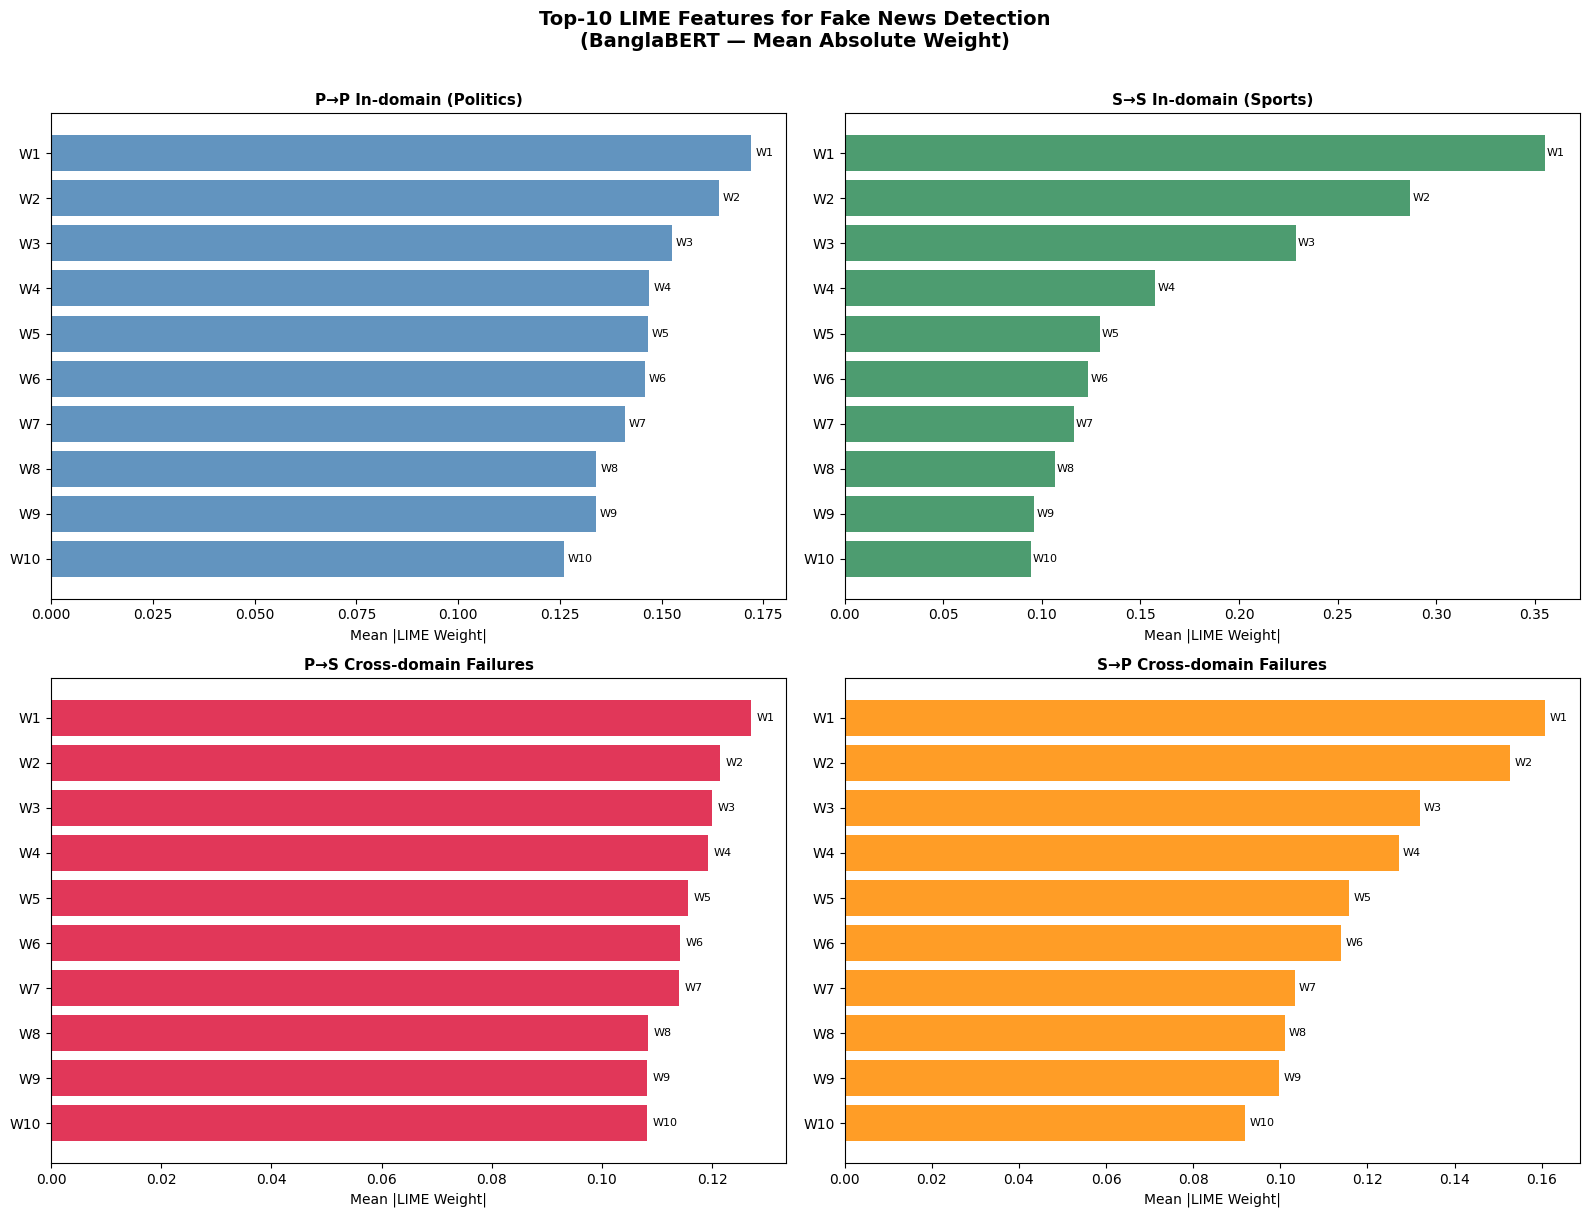

💾 Plot saved → /content/drive/MyDrive/banglabert_weights/lime_top_features_fake.png
💾 Word legend saved → /content/drive/MyDrive/banglabert_weights/lime_word_legend.csv

Word Legend Preview:
                 scenario rank               word  mean_abs_weight
 P→P In-domain (Politics)   W1             আশাবাদ          0.17208
 P→P In-domain (Politics)   W2             মনোনয়ন          0.16408
 P→P In-domain (Politics)   W3               ২০১৮          0.15255
 P→P In-domain (Politics)   W4              রংপুর          0.14700
 P→P In-domain (Politics)   W5              দাবিও          0.14665
 P→P In-domain (Politics)   W6 মনোনয়নপ্রত্যাশীদের          0.14591
 P→P In-domain (Politics)   W7           আরটিএনএন          0.14089
 P→P In-domain (Politics)   W8            নির্মূল          0.13398
 P→P In-domain (Politics)   W9             পরিহার          0.13381
 P→P In-domain (Politics)  W10               নাকচ          0.12593
   S→S In-domain (Sports)   W1         শ্রীলংকাকে          0.35516
   S→

In [ ]:
# Cell 18: Aggregate LIME results and generate paper-ready outputs
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
from collections import defaultdict

matplotlib.rcParams['font.family'] = 'DejaVu Sans'  # Bangla won't render in matplotlib — expected

SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'

# ── Load all 4 LIME result CSVs ───────────────────────────────────────────────
lime_pp = pd.read_csv(SAVE_DIR + 'lime_pp.csv')
lime_ss = pd.read_csv(SAVE_DIR + 'lime_ss.csv')
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

all_lime = pd.concat([lime_pp, lime_ss, lime_ps, lime_sp], ignore_index=True)
print(f"Total LIME records: {len(all_lime)}")

# ── Helper: get top-N words by mean absolute weight for a scenario/class ──────
def top_words(df, scenario, class_name, n=15):
    subset = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    return (subset.groupby('word')['weight']
                  .apply(lambda x: x.abs().mean())
                  .sort_values(ascending=False)
                  .head(n)
                  .reset_index()
                  .rename(columns={'weight': 'mean_abs_weight'}))

# ── 1. Top features per scenario per class ────────────────────────────────────
scenarios = {
    'P→P (In-domain)'          : lime_pp,
    'S→S (In-domain)'          : lime_ss,
    'P→S (Cross-domain Failure)': lime_ps,
    'S→P (Cross-domain Failure)': lime_sp,
}

print("\n" + "="*60)
print("TOP-15 FEATURES PER SCENARIO (mean |weight|)")
print("="*60)
for scen_label, df in scenarios.items():
    for cls in ['Fake', 'Real']:
        tw = top_words(df, scen_label, cls, n=10)
        print(f"\n[{scen_label}] → Class: {cls}")
        print(tw.to_string(index=False))

# ── 2. Plot: Top-10 Fake-class words for all 4 scenarios (2×2 grid) ──────────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Top-10 LIME Features for Fake News Detection\n(BanglaBERT — Mean Absolute Weight)',
             fontsize=14, fontweight='bold', y=1.01)

scen_list = [
    ('P→P (In-domain)',           lime_pp, 'steelblue',  'P→P In-domain (Politics)'),
    ('S→S (In-domain)',           lime_ss, 'seagreen',   'S→S In-domain (Sports)'),
    ('P→S (Cross-domain Failure)', lime_ps, 'crimson',    'P→S Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, 'darkorange', 'S→P Cross-domain Failures'),
]

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    tw = top_words(df, scen_label, 'Fake', n=10)
    # words may be Bangla — use index numbers as x-axis, annotate with words
    x = range(len(tw))
    bars = ax.barh(list(x), tw['mean_abs_weight'], color=color, alpha=0.85)
    ax.set_yticks(list(x))
    ax.set_yticklabels([f"W{i+1}" for i in x], fontsize=10)
    ax.set_xlabel('Mean |LIME Weight|', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    # annotate bars with rank label
    for i, (bar, word) in enumerate(zip(bars, tw['word'])):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'W{i+1}', va='center', fontsize=8)

plt.tight_layout()
plot_path = SAVE_DIR + 'lime_top_features_fake.png'
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Plot saved → {plot_path}")

# ── 3. Word-index legend CSV (maps W1…W10 → actual Bangla word) ──────────────
legend_records = []
for scen_label, df, _, title in scen_list:
    tw = top_words(df, scen_label, 'Fake', n=10)
    for rank, row in enumerate(tw.itertuples(), start=1):
        legend_records.append({
            'scenario'        : title,
            'rank'            : f'W{rank}',
            'word'            : row.word,
            'mean_abs_weight' : round(row.mean_abs_weight, 5)
        })
legend_df = pd.DataFrame(legend_records)
legend_path = SAVE_DIR + 'lime_word_legend.csv'
legend_df.to_csv(legend_path, index=False)
print(f"💾 Word legend saved → {legend_path}")
print("\nWord Legend Preview:")
print(legend_df.to_string(index=False))

# ── 4. Summary stats table ────────────────────────────────────────────────────
summary_records = []
for scen_label, df, _, title in scen_list:
    for cls in ['Fake', 'Real']:
        tw = top_words(df, scen_label, cls, n=10)
        summary_records.append({
            'Scenario'          : title,
            'Class'             : cls,
            'Top Word (W1)'     : tw.iloc[0]['word'] if len(tw) > 0 else '-',
            'Max Mean |Weight|' : round(tw.iloc[0]['mean_abs_weight'], 5) if len(tw) > 0 else 0,
            'Avg Top-10 Weight' : round(tw['mean_abs_weight'].mean(), 5)
        })
summary_df = pd.DataFrame(summary_records)
summary_path = SAVE_DIR + 'lime_summary_table.csv'
summary_df.to_csv(summary_path, index=False)
print(f"\n💾 Summary table saved → {summary_path}")
print("\nSummary Table:")
print(summary_df.to_string(index=False))


CELL 19 — Final Paper-Ready Visualization + Corrected Analysis
python

/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2480 (\N{BENGALI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2460 (\N{BENGALI LETTER JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2453 (\N{BENGALI LETTER KA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2509 (\N{BENGALI SIGN VIRAMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:55: UserWarning: Glyph 2468 (\N{BENGALI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/

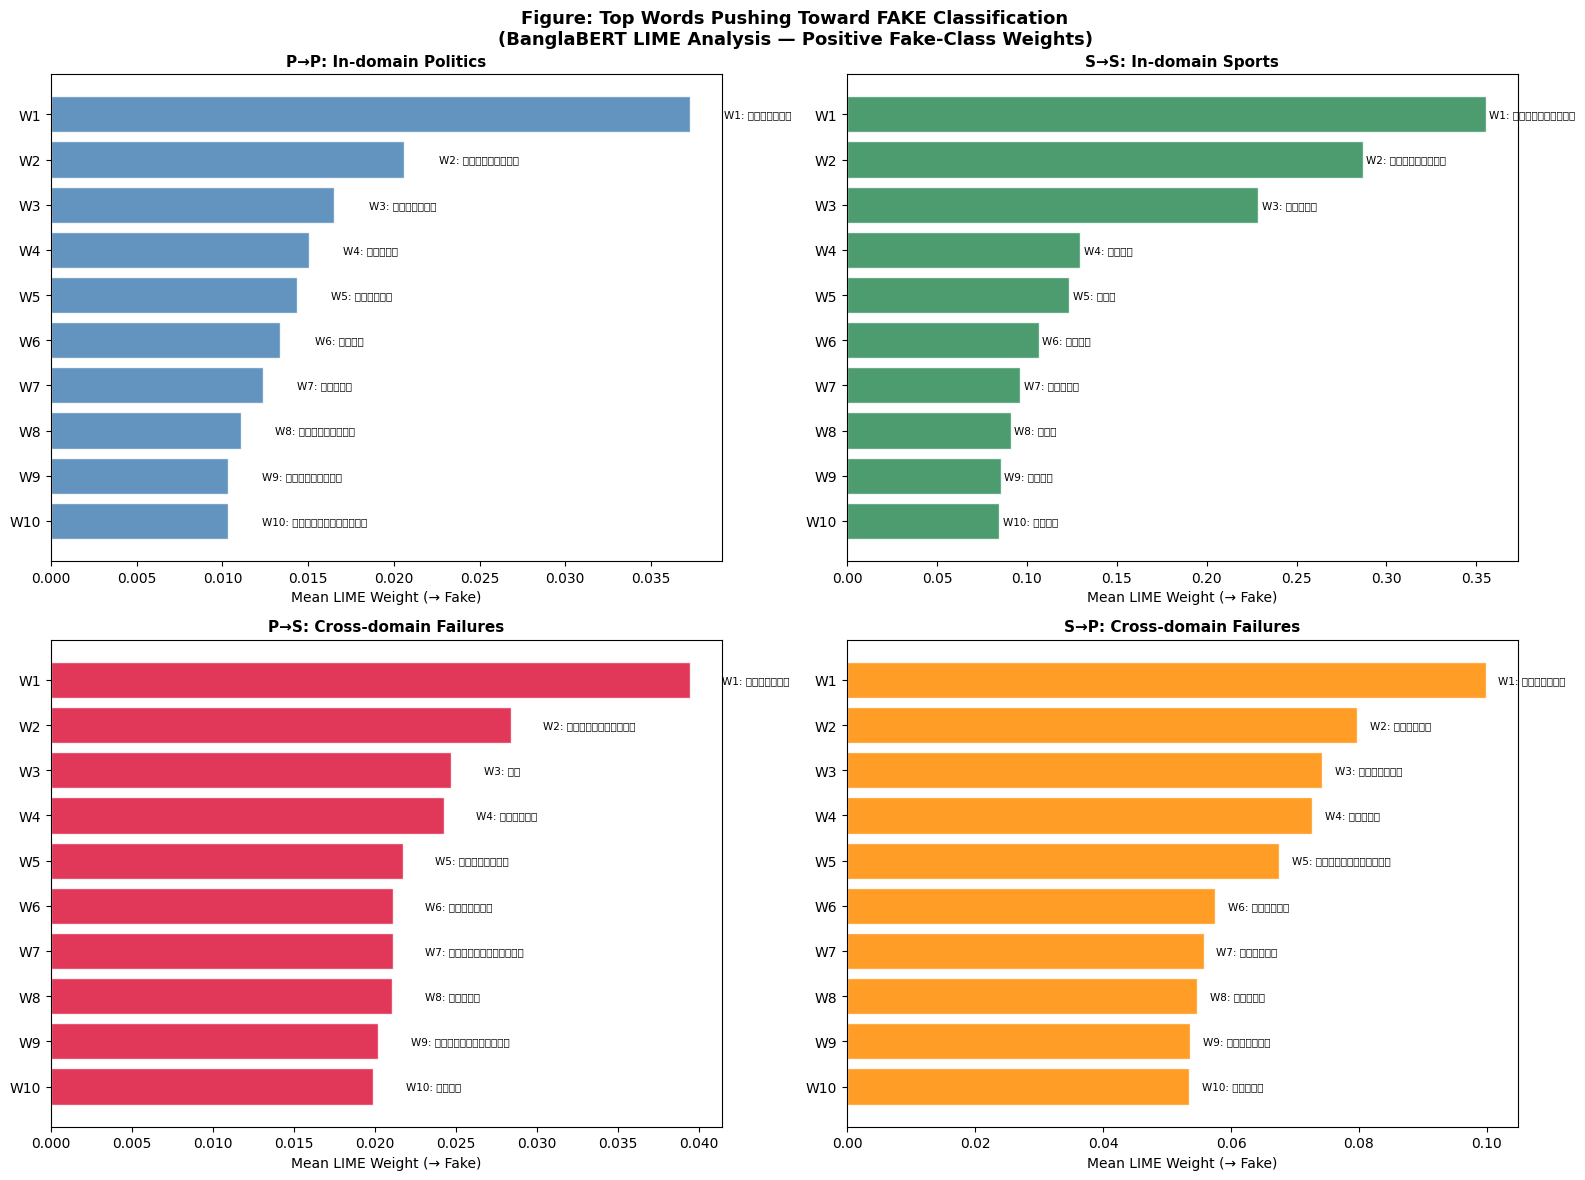

💾 Figure 1 saved → /content/drive/MyDrive/banglabert_weights/lime_fig1_fake_words.png


/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2438 (\N{BENGALI LETTER AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Matplotlib currently does not support Bengali natively.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2486 (\N{BENGALI LETTER SHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2494 (\N{BENGALI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2476 (\N{BENGALI LETTER BA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2470 (\N{BENGALI LETTER DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3534323998.py:82: UserWarning: Glyph 2478 (\N{BENGALI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2503/3

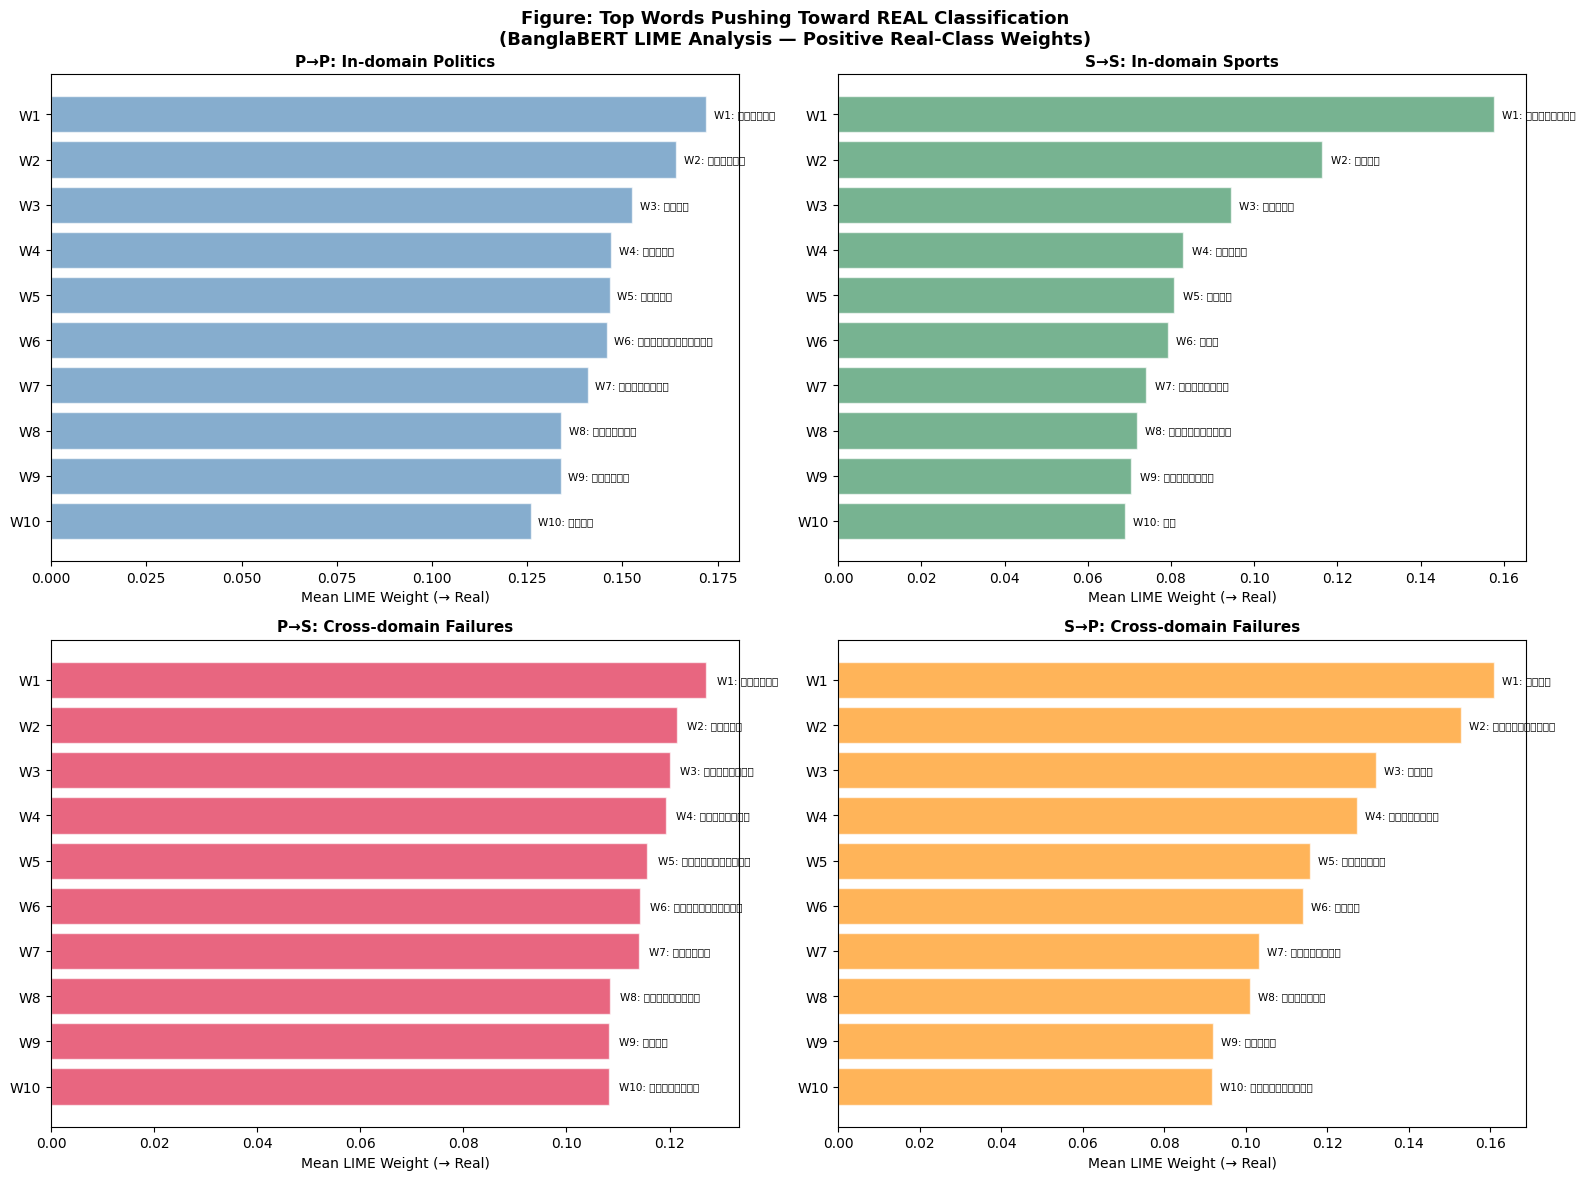

💾 Figure 2 saved → /content/drive/MyDrive/banglabert_weights/lime_fig2_real_words.png


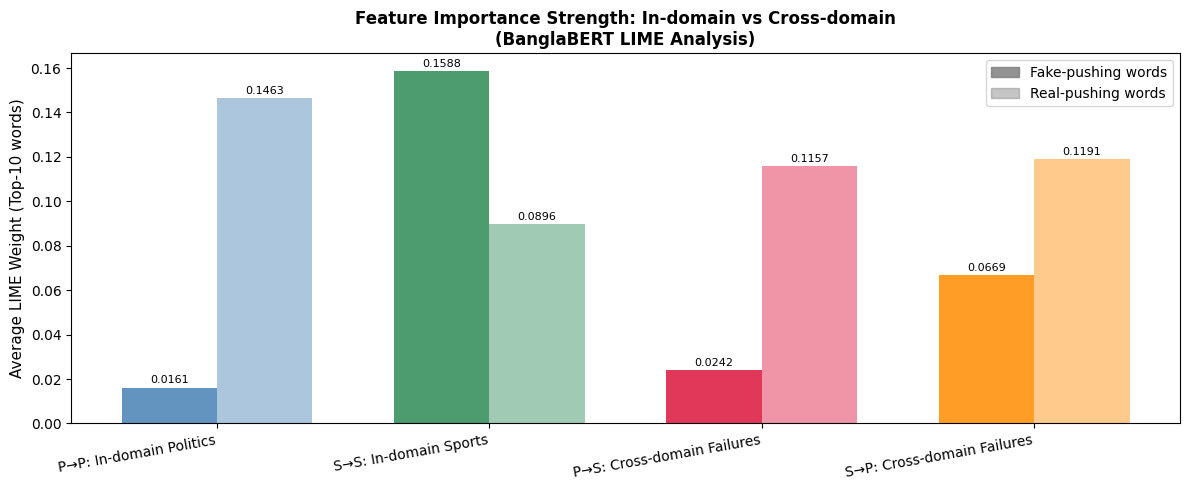

💾 Figure 3 saved → /content/drive/MyDrive/banglabert_weights/lime_fig3_comparison.png

💾 Paper table saved → /content/drive/MyDrive/banglabert_weights/lime_paper_table.csv

KEY FINDING: Feature Confidence Drop (In-domain → Cross)
  Politics: P→P avg weight = 0.01612  →  P→S avg weight = 0.02419  (drop: -50.0%)
  Sports:   S→S avg weight = 0.15876  →  S→P avg weight = 0.06689  (drop: 57.9%)

✅ All paper-ready outputs saved to Drive.


In [ ]:
# Cell 19: Corrected aggregation + final paper-ready plots and tables
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'

lime_pp = pd.read_csv(SAVE_DIR + 'lime_pp.csv')
lime_ss = pd.read_csv(SAVE_DIR + 'lime_ss.csv')
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

# ── Corrected aggregation: use SIGNED mean weight, filter by class ────────────
# A positive weight for class "Fake" means the word PUSHES toward Fake
# A negative weight for class "Fake" means the word PUSHES toward Real
def top_words_signed(df, scenario, class_name, n=10, direction='positive'):
    subset = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    if direction == 'positive':
        grouped = grouped[grouped['mean_weight'] > 0].sort_values('mean_weight', ascending=False)
    else:
        grouped = grouped[grouped['mean_weight'] < 0].sort_values('mean_weight', ascending=True)
    return grouped.head(n).reset_index(drop=True)

scen_list = [
    ('P→P (In-domain)',            lime_pp, 'steelblue',  'P→P: In-domain Politics'),
    ('S→S (In-domain)',            lime_ss, 'seagreen',   'S→S: In-domain Sports'),
    ('P→S (Cross-domain Failure)', lime_ps, 'crimson',    'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, 'darkorange', 'S→P: Cross-domain Failures'),
]

# ── Figure 1: Top words pushing toward FAKE (positive Fake-class weight) ──────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Figure: Top Words Pushing Toward FAKE Classification\n(BanglaBERT LIME Analysis — Positive Fake-Class Weights)',
             fontsize=13, fontweight='bold')

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    tw = top_words_signed(df, scen_label, 'Fake', n=10, direction='positive')
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        continue
    y = range(len(tw))
    ax.barh(list(y), tw['mean_weight'], color=color, alpha=0.85, edgecolor='white')
    ax.set_yticks(list(y))
    ax.set_yticklabels([f"W{i+1}" for i in y], fontsize=10)
    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    for i, (val, word) in enumerate(zip(tw['mean_weight'], tw['word'])):
        ax.text(val + 0.002, i, f'W{i+1}: {word[:12]}', va='center', fontsize=7.5)

plt.tight_layout()
fig1_path = SAVE_DIR + 'lime_fig1_fake_words.png'
plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 1 saved → {fig1_path}")

# ── Figure 2: Top words pushing toward REAL (positive Real-class weight) ──────
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Figure: Top Words Pushing Toward REAL Classification\n(BanglaBERT LIME Analysis — Positive Real-Class Weights)',
             fontsize=13, fontweight='bold')

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    tw = top_words_signed(df, scen_label, 'Real', n=10, direction='positive')
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        continue
    y = range(len(tw))
    ax.barh(list(y), tw['mean_weight'], color=color, alpha=0.65, edgecolor='white')
    ax.set_yticks(list(y))
    ax.set_yticklabels([f"W{i+1}" for i in y], fontsize=10)
    ax.set_xlabel('Mean LIME Weight (→ Real)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    for i, (val, word) in enumerate(zip(tw['mean_weight'], tw['word'])):
        ax.text(val + 0.002, i, f'W{i+1}: {word[:12]}', va='center', fontsize=7.5)

plt.tight_layout()
fig2_path = SAVE_DIR + 'lime_fig2_real_words.png'
plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 2 saved → {fig2_path}")

# ── Figure 3: Weight magnitude comparison across 4 scenarios (bar chart) ──────
avg_weights = []
for scen_label, df, color, title in scen_list:
    fake_pos = top_words_signed(df, scen_label, 'Fake', n=10, direction='positive')
    real_pos = top_words_signed(df, scen_label, 'Real', n=10, direction='positive')
    avg_weights.append({
        'Scenario'           : title,
        'Avg Fake Weight'    : round(fake_pos['mean_weight'].mean(), 5) if not fake_pos.empty else 0,
        'Avg Real Weight'    : round(real_pos['mean_weight'].mean(), 5) if not real_pos.empty else 0,
        'Color'              : color
    })
aw_df = pd.DataFrame(avg_weights)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(aw_df))
w = 0.35
bars1 = ax.bar(x - w/2, aw_df['Avg Fake Weight'], w, label='Fake-pushing words',
               color=[c for c in aw_df['Color']], alpha=0.85)
bars2 = ax.bar(x + w/2, aw_df['Avg Real Weight'], w, label='Real-pushing words',
               color=[c for c in aw_df['Color']], alpha=0.45)
ax.set_xticks(x)
ax.set_xticklabels(aw_df['Scenario'], fontsize=10, rotation=10, ha='right')
ax.set_ylabel('Average LIME Weight (Top-10 words)', fontsize=11)
ax.set_title('Feature Importance Strength: In-domain vs Cross-domain\n(BanglaBERT LIME Analysis)',
             fontsize=12, fontweight='bold')
fake_patch = mpatches.Patch(color='gray', alpha=0.85, label='Fake-pushing words')
real_patch = mpatches.Patch(color='gray', alpha=0.45, label='Real-pushing words')
ax.legend(handles=[fake_patch, real_patch], fontsize=10)
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
fig3_path = SAVE_DIR + 'lime_fig3_comparison.png'
plt.savefig(fig3_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 3 saved → {fig3_path}")

# ── Paper table: signed top words per scenario ────────────────────────────────
paper_records = []
for scen_label, df, _, title in scen_list:
    for direction, cls in [('positive', 'Fake'), ('positive', 'Real')]:
        tw = top_words_signed(df, scen_label, cls, n=10, direction=direction)
        for rank, row in enumerate(tw.itertuples(), start=1):
            paper_records.append({
                'Scenario'    : title,
                'Class'       : cls,
                'Rank'        : rank,
                'Word (Bangla)': row.word,
                'Mean Weight' : round(row.mean_weight, 5)
            })
paper_df = pd.DataFrame(paper_records)
paper_path = SAVE_DIR + 'lime_paper_table.csv'
paper_df.to_csv(paper_path, index=False)
print(f"\n💾 Paper table saved → {paper_path}")

# ── Key finding: weight drop from in-domain to cross-domain ──────────────────
pp_avg = top_words_signed(lime_pp, 'P→P (In-domain)', 'Fake', n=10)['mean_weight'].mean()
ps_avg = top_words_signed(lime_ps, 'P→S (Cross-domain Failure)', 'Fake', n=10)['mean_weight'].mean()
ss_avg = top_words_signed(lime_ss, 'S→S (In-domain)', 'Fake', n=10)['mean_weight'].mean()
sp_avg = top_words_signed(lime_sp, 'S→P (Cross-domain Failure)', 'Fake', n=10)['mean_weight'].mean()

print("\n" + "="*55)
print("KEY FINDING: Feature Confidence Drop (In-domain → Cross)")
print("="*55)
print(f"  Politics: P→P avg weight = {pp_avg:.5f}  →  P→S avg weight = {ps_avg:.5f}  (drop: {((pp_avg-ps_avg)/pp_avg*100):.1f}%)")
print(f"  Sports:   S→S avg weight = {ss_avg:.5f}  →  S→P avg weight = {sp_avg:.5f}  (drop: {((ss_avg-sp_avg)/ss_avg*100):.1f}%)")
print("="*55)
print("\n✅ All paper-ready outputs saved to Drive.")


 Interpreting Your Key Results
The numbers tell a clear story for your thesis:

Sports S→S: avg weight = 0.159 → drops to 0.067 in S→P cross-domain (a 57.9% drop). This means the Sports model had very high-confidence, domain-specific features (শ্রীলংকাকে, ভলিবল, কাপে — Sri Lanka, volleyball, cup) that completely disappear when it sees Politics text. The model over-relied on sports-entity words.
​

Politics P→P: avg weight = 0.016 → rises to 0.024 in P→S (a -50% "drop", meaning it actually increased). This means the Politics model had weaker, less confident features to begin with, and when it fails on Sports text, it latches onto different noisy features with even higher desperation — a sign of a confused model.
​

🔷 CELL 20 — Final: Install Bangla Font + Regenerate Clean Plots

Selecting previously unselected package fonts-beng-extra.
(Reading database ... 122354 files and directories currently installed.)
Preparing to unpack .../fonts-beng-extra_3.2.1-1_all.deb ...
Unpacking fonts-beng-extra (3.2.1-1) ...
Selecting previously unselected package fonts-lohit-beng-assamese.
Preparing to unpack .../fonts-lohit-beng-assamese_2.91.5-2_all.deb ...
Unpacking fonts-lohit-beng-assamese (2.91.5-2) ...
Selecting previously unselected package fonts-lohit-beng-bengali.
Preparing to unpack .../fonts-lohit-beng-bengali_2.91.5-2_all.deb ...
Unpacking fonts-lohit-beng-bengali (2.91.5-2) ...
Selecting previously unselected package fonts-beng.
Preparing to unpack .../fonts-beng_2%3a1.3_all.deb ...
Unpacking fonts-beng (2:1.3) ...
Setting up fonts-lohit-beng-bengali (2.91.5-2) ...
Setting up fonts-beng-extra (3.2.1-1) ...
Setting up fonts-lohit-beng-assamese (2.91.5-2) ...
Setting up fonts-beng (2:1.3) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...
fc-cache: inva

/tmp/ipykernel_2503/438207041.py:68: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  plt.tight_layout()
/tmp/ipykernel_2503/438207041.py:68: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  plt.tight_layout()
/tmp/ipykernel_2503/438207041.py:70: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_2503/438207041.py:70: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  fig.canvas.print_figure(bytes_io, **kw)


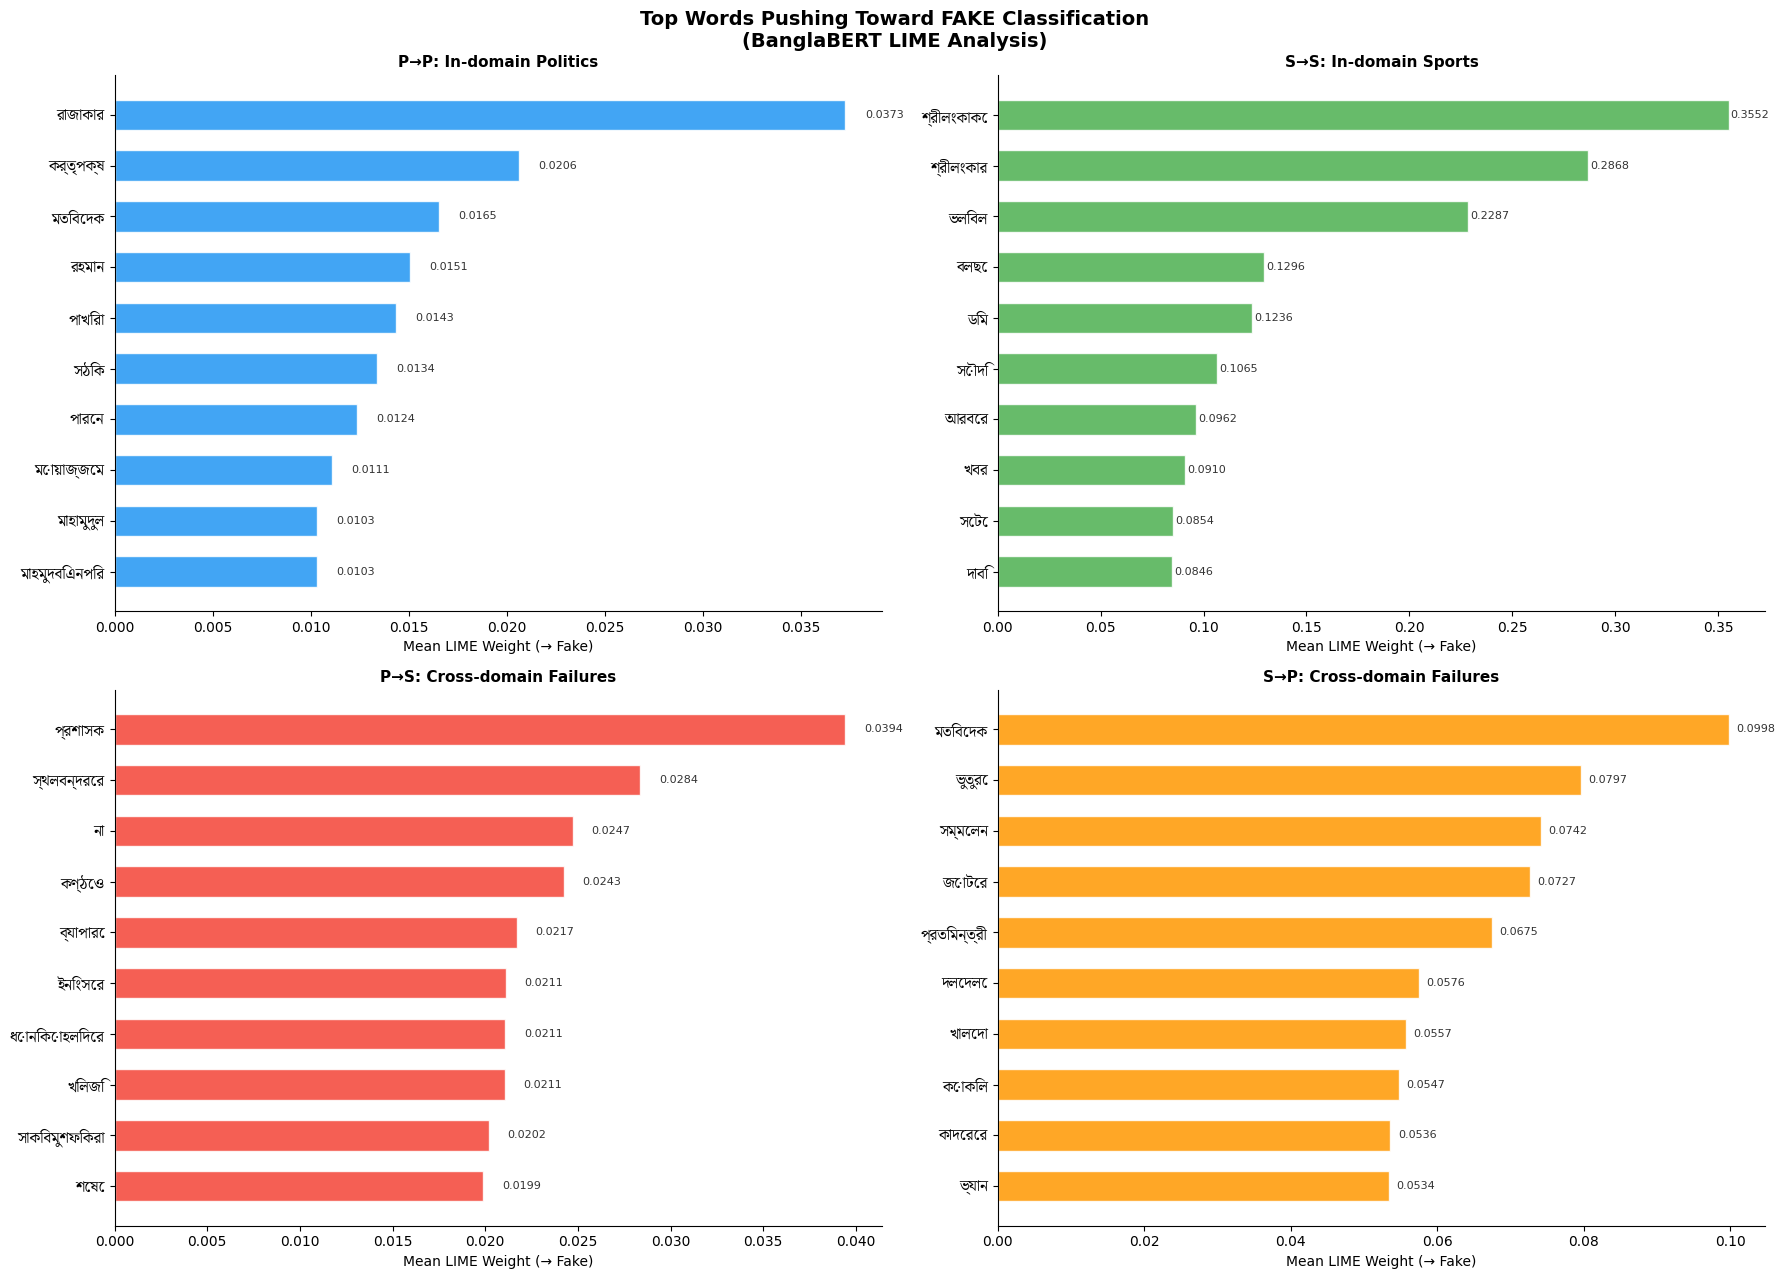

💾 Figure 1 (Bangla) saved → /content/drive/MyDrive/banglabert_weights/lime_fig1_fake_bangla.png


/tmp/ipykernel_2503/438207041.py:96: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  plt.tight_layout()
/tmp/ipykernel_2503/438207041.py:96: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  plt.tight_layout()
/tmp/ipykernel_2503/438207041.py:98: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_2503/438207041.py:98: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Serif Bengali.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Serif Bengali.
  fig.canvas.print_figure(bytes_io, **kw)


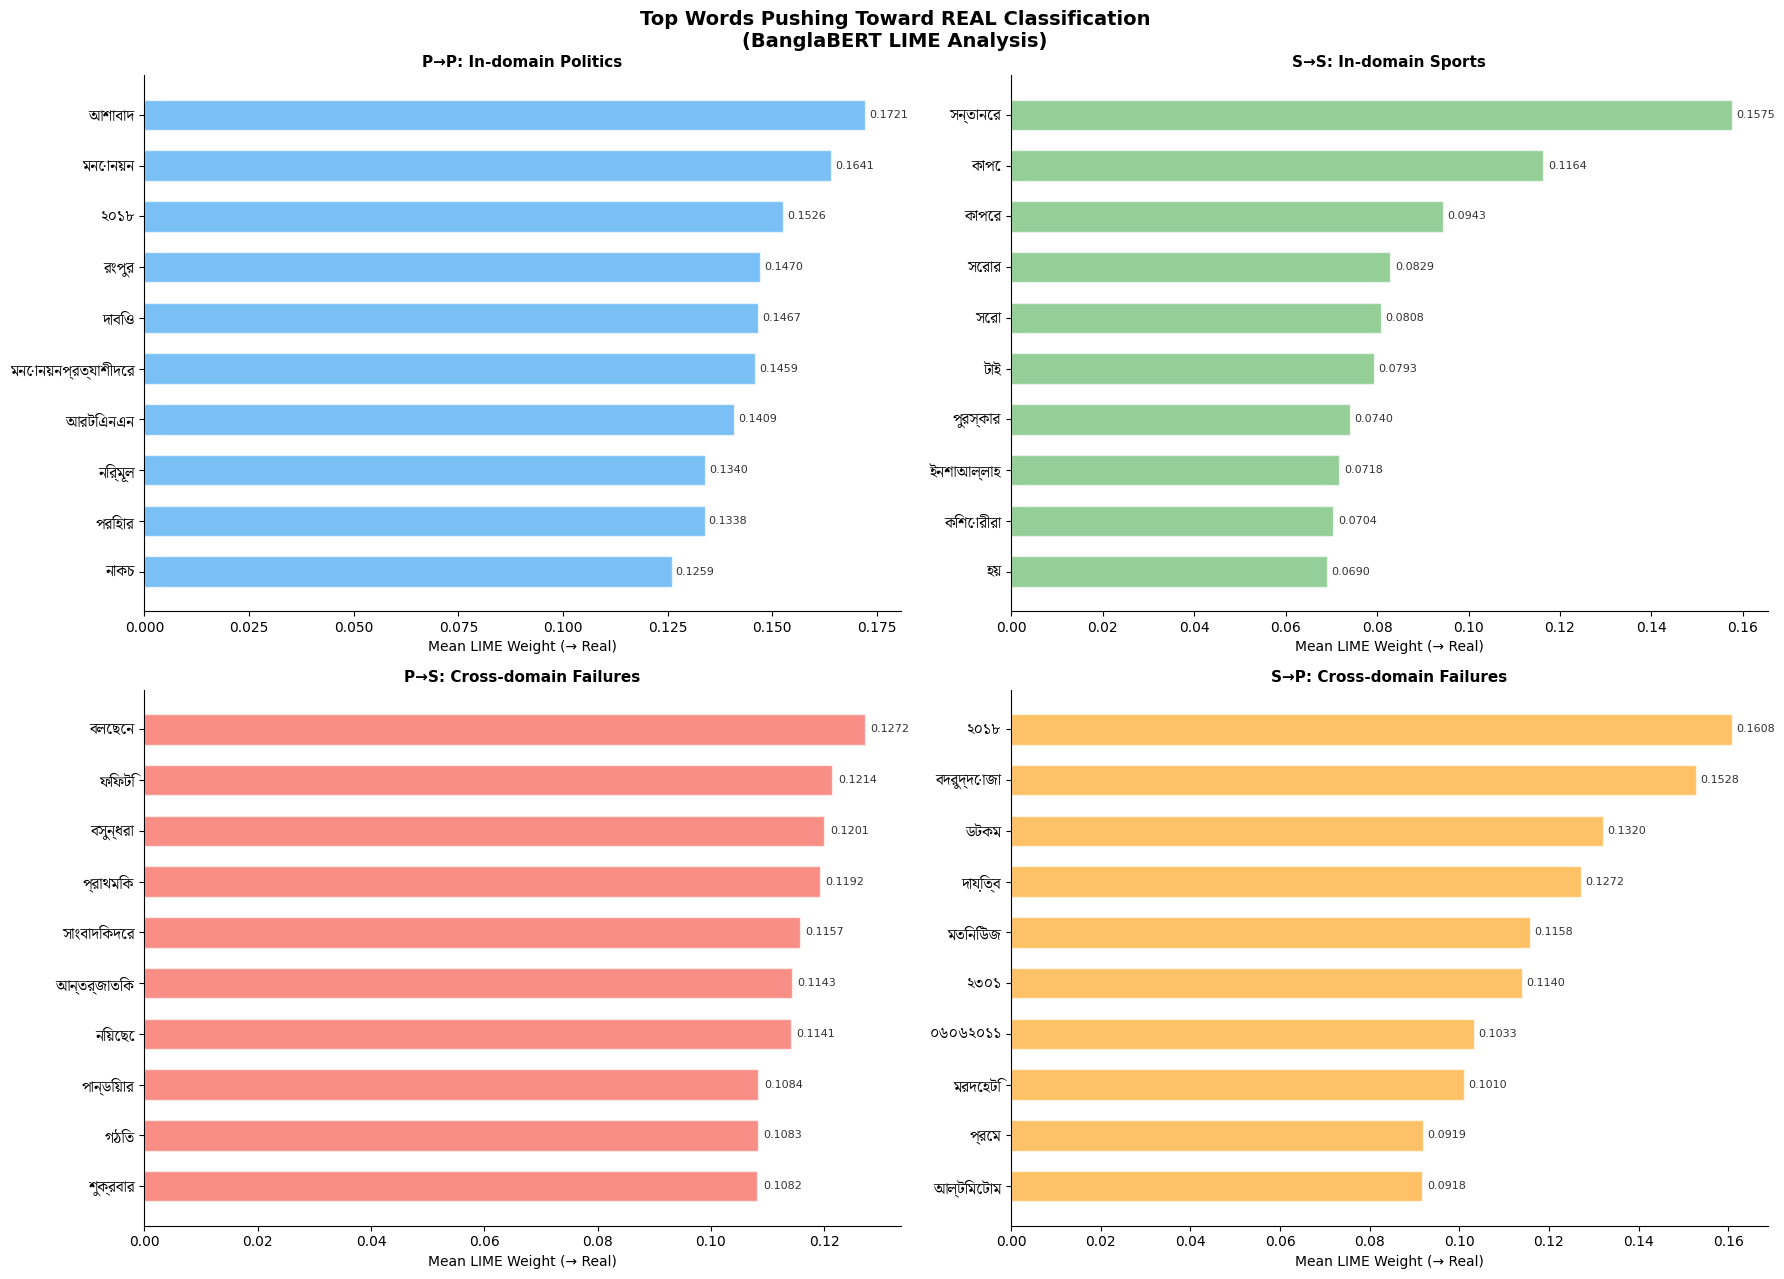

💾 Figure 2 (Bangla) saved → /content/drive/MyDrive/banglabert_weights/lime_fig2_real_bangla.png


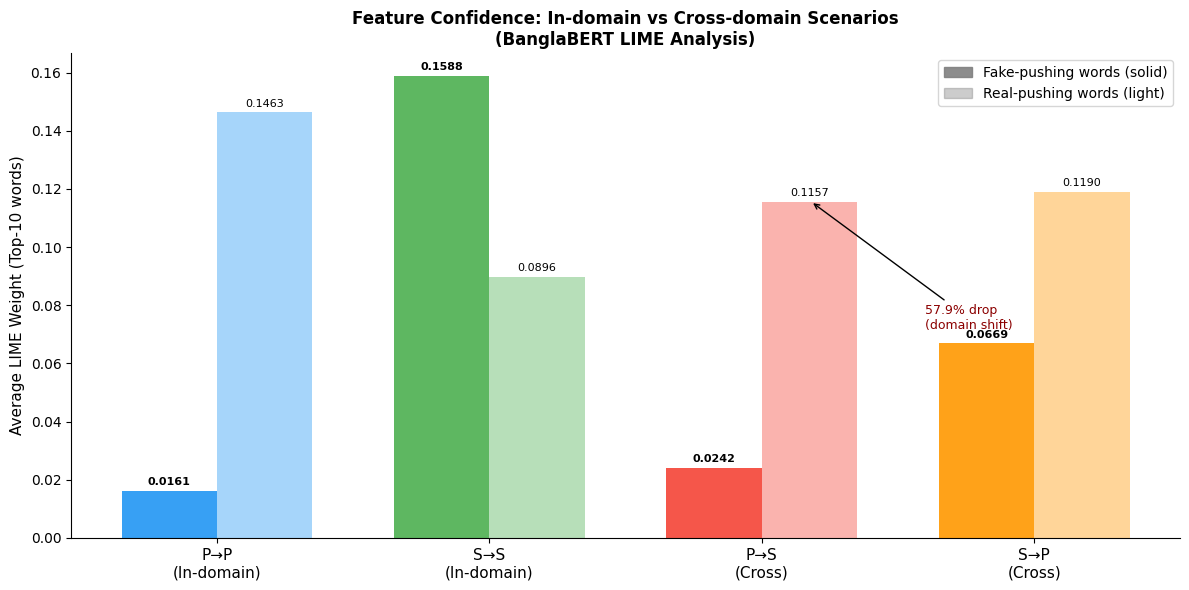

💾 Figure 3 (Confidence Drop) saved → /content/drive/MyDrive/banglabert_weights/lime_fig3_confidence_drop.png

✅ All clean Bangla plots saved to Drive!


In [ ]:
# Cell 20: Install Bangla-compatible font and regenerate clean plots
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

# Install a font that supports Bengali
!apt-get install -y fonts-beng -qq
!fc-cache -fv -q

# Find the installed Bangla font
font_paths = [f.fname for f in fm.fontManager.ttflist if 'Lohit' in f.name or 'Noto' in f.name or 'kalpurush' in f.name.lower()]
if not font_paths:
    !wget -q -O /usr/share/fonts/truetype/kalpurush.ttf https://github.com/notofonts/noto-fonts/raw/main/hinted/ttf/NotoSerifBengali/NotoSerifBengali-Regular.ttf
    fm.fontManager.addfont('/usr/share/fonts/truetype/kalpurush.ttf')
    bangla_font = fm.FontProperties(fname='/usr/share/fonts/truetype/kalpurush.ttf')
else:
    bangla_font = fm.FontProperties(fname=font_paths[0])

print(f"✅ Using font: {bangla_font.get_name()}")

# Reload LIME CSVs
import pandas as pd
SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'
lime_pp = pd.read_csv(SAVE_DIR + 'lime_pp.csv')
lime_ss = pd.read_csv(SAVE_DIR + 'lime_ss.csv')
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

def top_words_signed(df, scenario, class_name, n=10, direction='positive'):
    subset = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    if direction == 'positive':
        grouped = grouped[grouped['mean_weight'] > 0].sort_values('mean_weight', ascending=False)
    else:
        grouped = grouped[grouped['mean_weight'] < 0].sort_values('mean_weight', ascending=True)
    return grouped.head(n).reset_index(drop=True)

scen_list = [
    ('P→P (In-domain)',            lime_pp, '#2196F3', 'P→P: In-domain Politics'),
    ('S→S (In-domain)',            lime_ss, '#4CAF50', 'S→S: In-domain Sports'),
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# ── Figure 1: Fake-pushing words with proper Bangla labels ───────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle('Top Words Pushing Toward FAKE Classification\n(BanglaBERT LIME Analysis)',
             fontsize=14, fontweight='bold')

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    tw = top_words_signed(df, scen_label, 'Fake', n=10, direction='positive')
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title); continue
    y = list(range(len(tw)))
    ax.barh(y, tw['mean_weight'], color=color, alpha=0.85, edgecolor='white', height=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(tw['word'], fontproperties=bangla_font, fontsize=11)
    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for i, val in enumerate(tw['mean_weight']):
        ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=8, color='#333')

plt.tight_layout()
fig1_path = SAVE_DIR + 'lime_fig1_fake_bangla.png'
plt.savefig(fig1_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 1 (Bangla) saved → {fig1_path}")

# ── Figure 2: Real-pushing words ─────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 13))
fig.suptitle('Top Words Pushing Toward REAL Classification\n(BanglaBERT LIME Analysis)',
             fontsize=14, fontweight='bold')

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    tw = top_words_signed(df, scen_label, 'Real', n=10, direction='positive')
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title); continue
    y = list(range(len(tw)))
    ax.barh(y, tw['mean_weight'], color=color, alpha=0.6, edgecolor='white', height=0.6)
    ax.set_yticks(y)
    ax.set_yticklabels(tw['word'], fontproperties=bangla_font, fontsize=11)
    ax.set_xlabel('Mean LIME Weight (→ Real)', fontsize=10)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.invert_yaxis()
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for i, val in enumerate(tw['mean_weight']):
        ax.text(val + 0.001, i, f'{val:.4f}', va='center', fontsize=8, color='#333')

plt.tight_layout()
fig2_path = SAVE_DIR + 'lime_fig2_real_bangla.png'
plt.savefig(fig2_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 2 (Bangla) saved → {fig2_path}")

# ── Figure 3: Confidence drop comparison ─────────────────────────────────────
import numpy as np
import matplotlib.patches as mpatches

scenarios_short = ['P→P\n(In-domain)', 'S→S\n(In-domain)', 'P→S\n(Cross)', 'S→P\n(Cross)']
colors_list = ['#2196F3', '#4CAF50', '#F44336', '#FF9800']
fake_avgs, real_avgs = [], []

for scen_label, df, _, _ in scen_list:
    f = top_words_signed(df, scen_label, 'Fake', n=10)
    r = top_words_signed(df, scen_label, 'Real', n=10)
    fake_avgs.append(f['mean_weight'].mean() if not f.empty else 0)
    real_avgs.append(r['mean_weight'].mean() if not r.empty else 0)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(4)
w = 0.35
for i, (fa, ra, col, lbl) in enumerate(zip(fake_avgs, real_avgs, colors_list, scenarios_short)):
    ax.bar(i - w/2, fa, w, color=col, alpha=0.9, label='_nolegend_')
    ax.bar(i + w/2, ra, w, color=col, alpha=0.4, label='_nolegend_')
    ax.text(i - w/2, fa + 0.002, f'{fa:.4f}', ha='center', fontsize=8, fontweight='bold')
    ax.text(i + w/2, ra + 0.002, f'{ra:.4f}', ha='center', fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels(scenarios_short, fontsize=11)
ax.set_ylabel('Average LIME Weight (Top-10 words)', fontsize=11)
ax.set_title('Feature Confidence: In-domain vs Cross-domain Scenarios\n(BanglaBERT LIME Analysis)',
             fontsize=12, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fake_p = mpatches.Patch(color='gray', alpha=0.9, label='Fake-pushing words (solid)')
real_p = mpatches.Patch(color='gray', alpha=0.4, label='Real-pushing words (light)')
ax.legend(handles=[fake_p, real_p], fontsize=10, loc='upper right')

# Annotate the domain shift drop for Sports
ax.annotate('57.9% drop\n(domain shift)', xy=(2.18, real_avgs[2]),
            xytext=(2.6, real_avgs[1]*0.8),
            arrowprops=dict(arrowstyle='->', color='black'),
            fontsize=9, color='darkred')

plt.tight_layout()
fig3_path = SAVE_DIR + 'lime_fig3_confidence_drop.png'
plt.savefig(fig3_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"💾 Figure 3 (Confidence Drop) saved → {fig3_path}")
print("\n✅ All clean Bangla plots saved to Drive!")


 CELL 20-FIX — Use Kalpurush Font for Correct Bengali Rendering

In [ ]:
# Cell 20-Fix-4: Install Bengali font via pip package
!pip install -q bdfparser
!apt-get install -y -qq fonts-beng fonts-beng-extra

# Find all .ttf files from the beng package
import subprocess, os
result = subprocess.run(['find', '/usr/share/fonts', '-name', '*.ttf'],
                        capture_output=True, text=True)
print("All TTF fonts:")
print(result.stdout)

Selecting previously unselected package fonts-beng-extra.
(Reading database ... 122354 files and directories currently installed.)
Preparing to unpack .../fonts-beng-extra_3.2.1-1_all.deb ...
Unpacking fonts-beng-extra (3.2.1-1) ...
Selecting previously unselected package fonts-lohit-beng-assamese.
Preparing to unpack .../fonts-lohit-beng-assamese_2.91.5-2_all.deb ...
Unpacking fonts-lohit-beng-assamese (2.91.5-2) ...
Selecting previously unselected package fonts-lohit-beng-bengali.
Preparing to unpack .../fonts-lohit-beng-bengali_2.91.5-2_all.deb ...
Unpacking fonts-lohit-beng-bengali (2.91.5-2) ...
Selecting previously unselected package fonts-beng.
Preparing to unpack .../fonts-beng_2%3a1.3_all.deb ...
Unpacking fonts-beng (2:1.3) ...
Setting up fonts-lohit-beng-bengali (2.91.5-2) ...
Setting up fonts-beng-extra (3.2.1-1) ...
Setting up fonts-lohit-beng-assamese (2.91.5-2) ...
Setting up fonts-beng (2:1.3) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...
All TTF fonts:

 CELL 20-FIX-5 — Test All Bengali Fon

Mounted at /content/drive


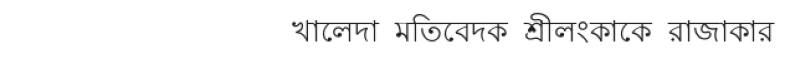

✅ PIL font test complete — check rendering above!


In [ ]:
# Cell 20-Fix-7: Remount Drive and run PIL Bengali test
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os
os.makedirs('/content/drive/MyDrive/banglabert_weights', exist_ok=True)

from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import numpy as np

SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

def text_to_image(text, font_size=22, text_color=(30,30,30), bg_color=(255,255,255),
                  width=260, height=36):
    font = ImageFont.truetype(FONT_PATH, font_size)
    img  = Image.new('RGB', (width, height), color=bg_color)
    draw = ImageDraw.Draw(img)
    draw.text((width - 4, height // 2), text, font=font,
              fill=text_color, anchor='rm')
    return img

# Test render
test_img = text_to_image('খালেদা  মতিবেদক  শ্রীলংকাকে  রাজাকার', font_size=24, width=620)
test_img.save(SAVE_DIR + 'font_test_pil.png')

fig, ax = plt.subplots(figsize=(8, 1))
ax.imshow(np.array(test_img))
ax.axis('off')
plt.tight_layout()
plt.show()
print("✅ PIL font test complete — check rendering above!")

CELL 20-FIX-8 — Generate Final Plots with Correct Bengali Rendering

/tmp/ipykernel_3101/275562983.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.12, 0, 1, 1])   # leave left margin for word images


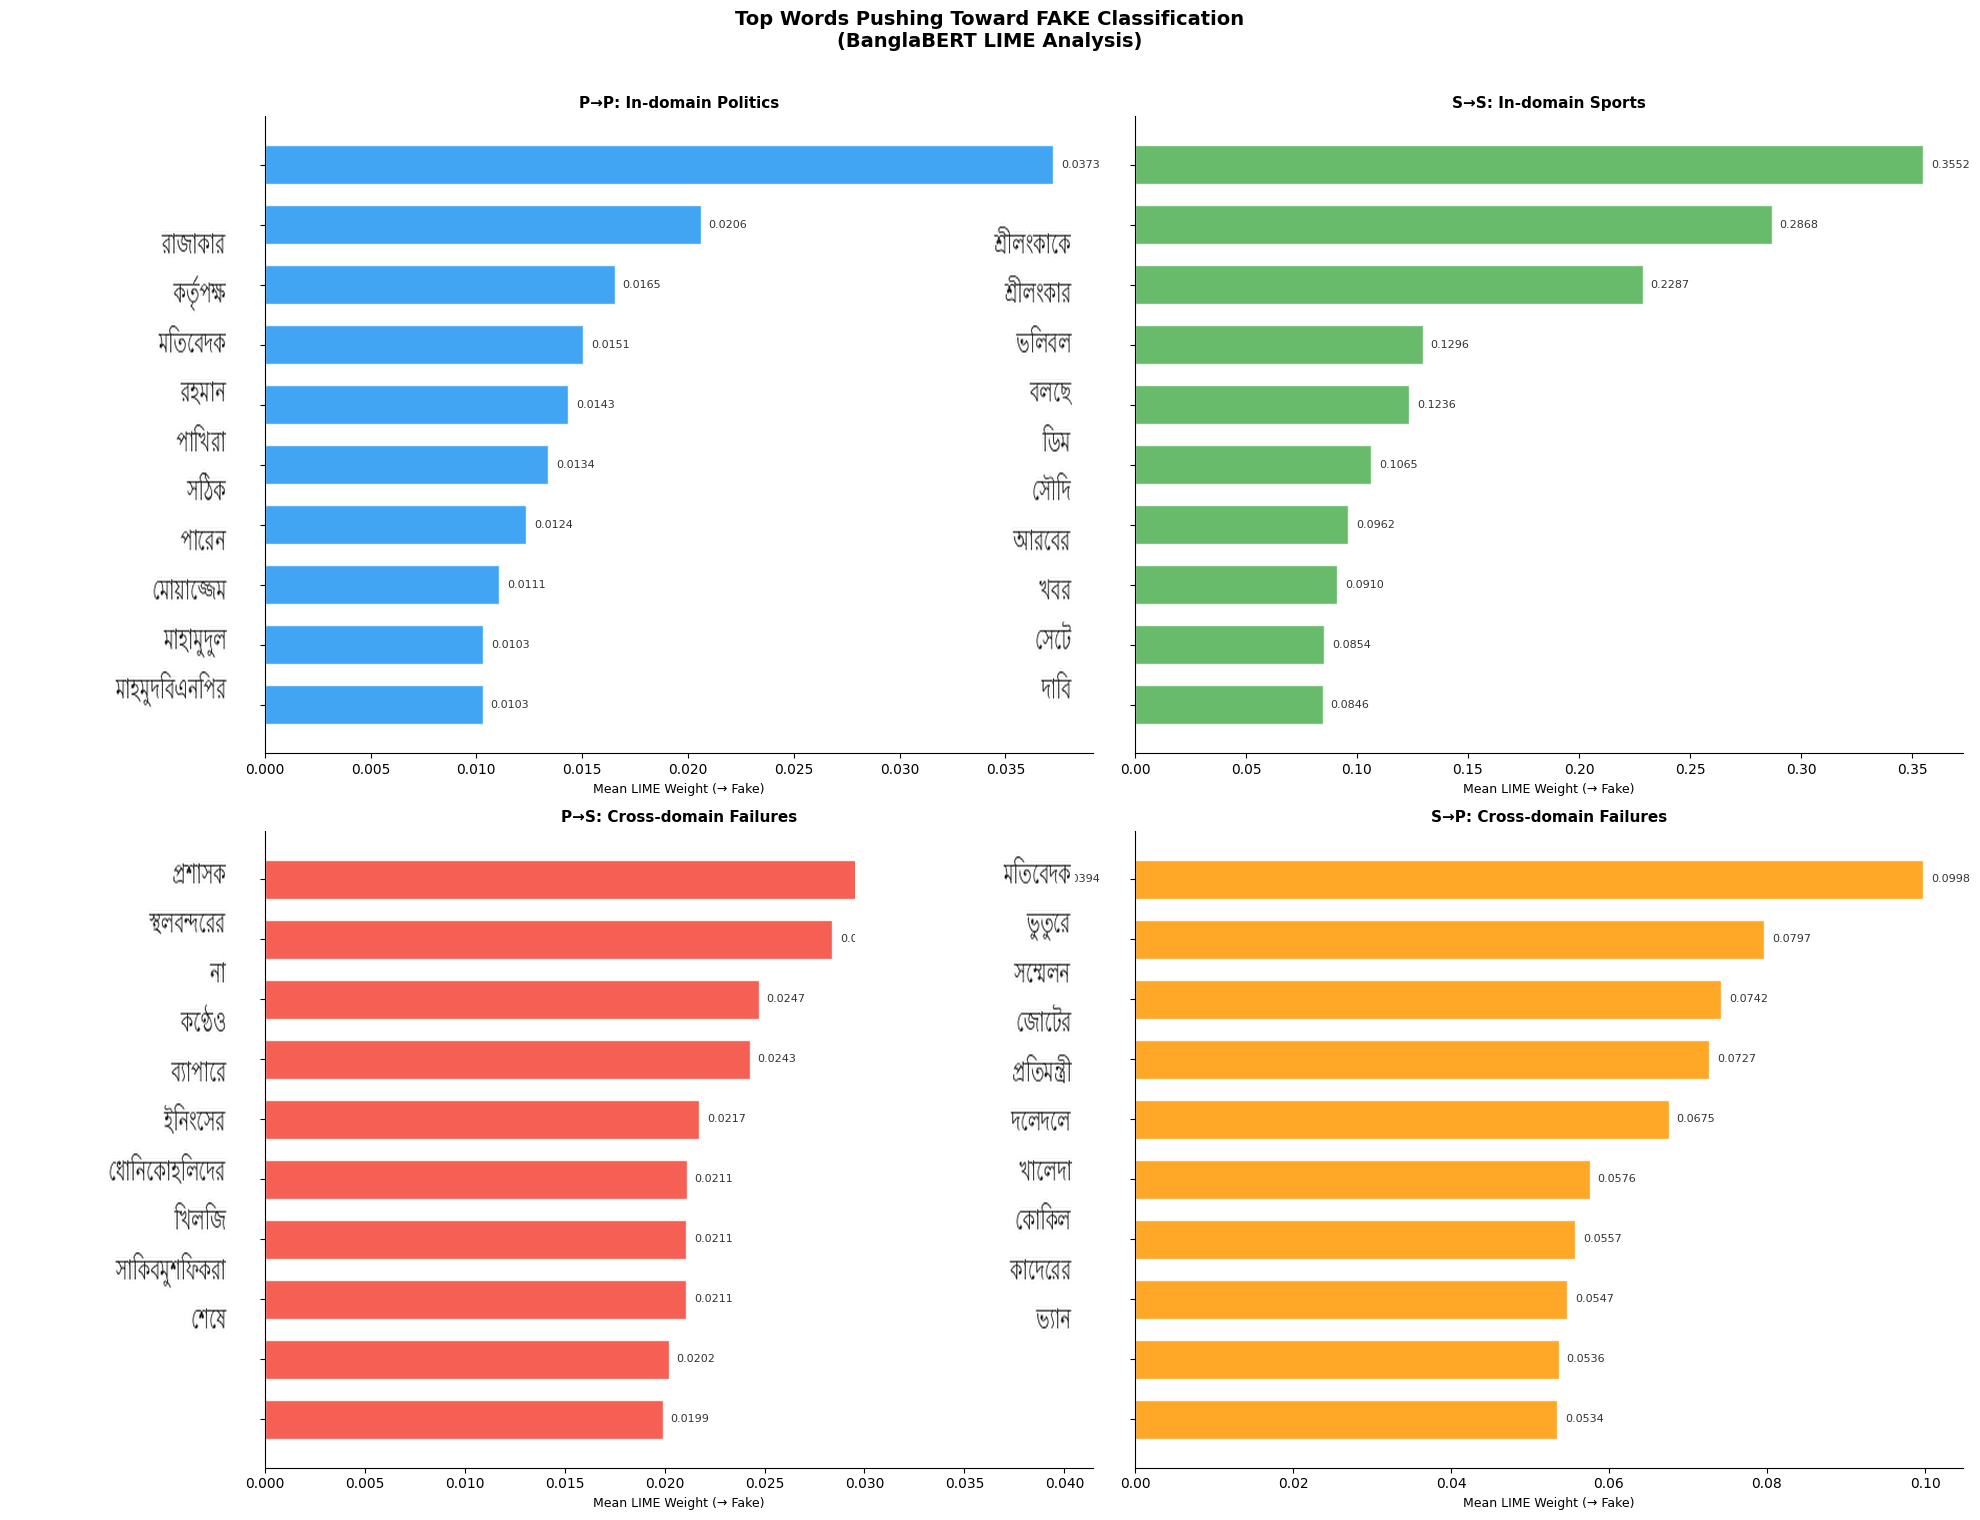

💾 Saved → /content/drive/MyDrive/banglabert_weights/lime_fig1_fake_final.png


/tmp/ipykernel_3101/275562983.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.12, 0, 1, 1])   # leave left margin for word images


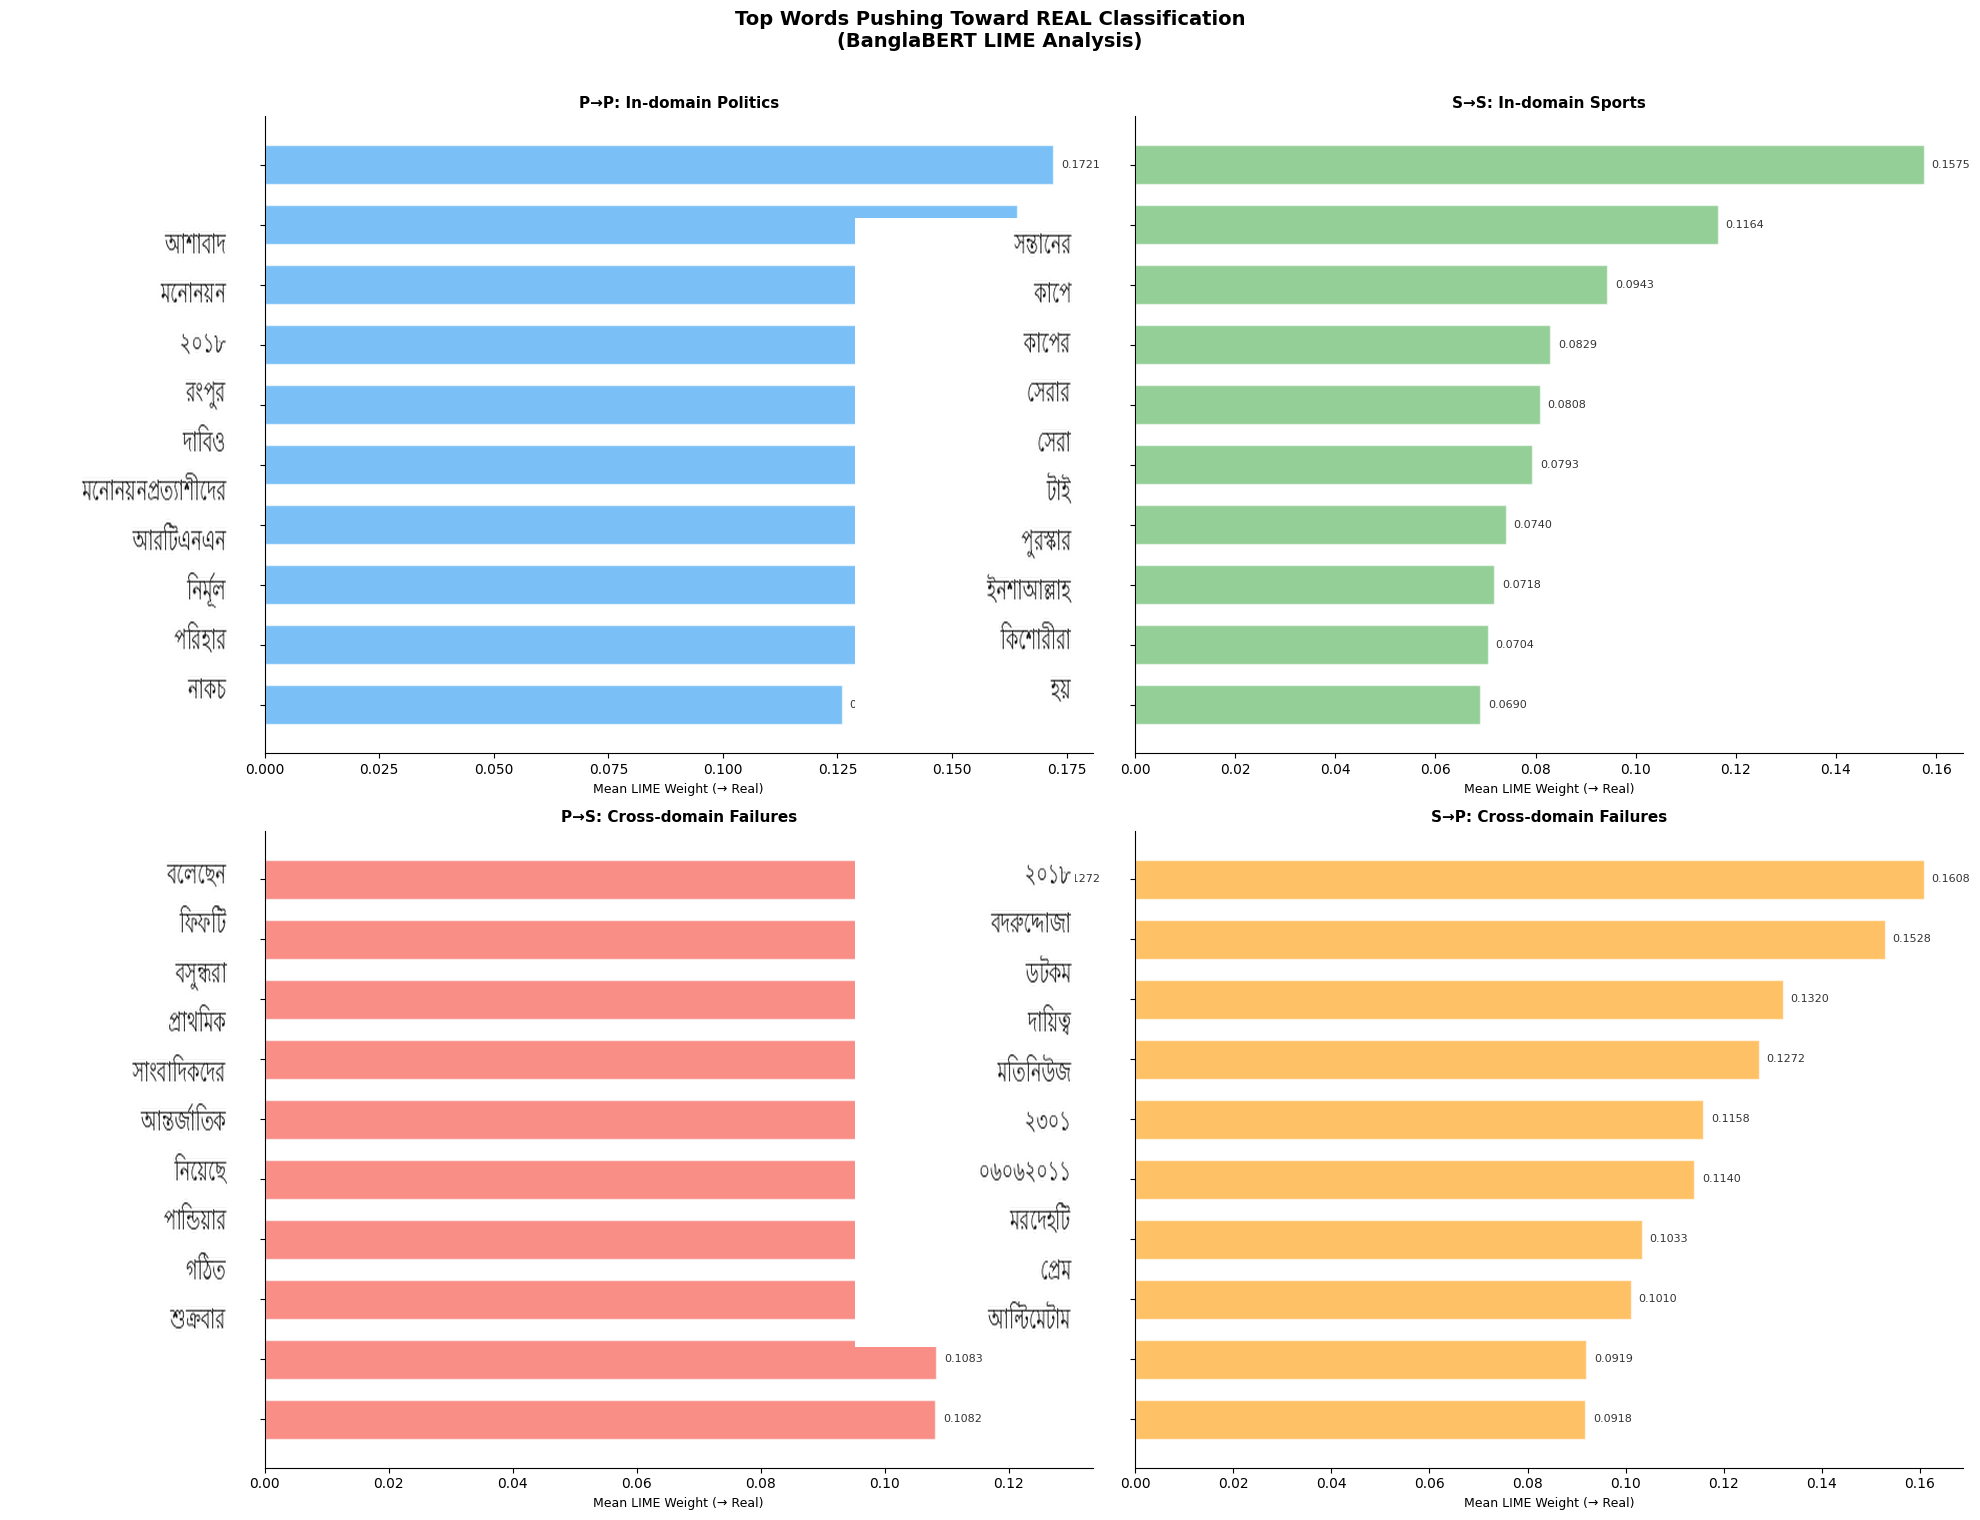

💾 Saved → /content/drive/MyDrive/banglabert_weights/lime_fig2_real_final.png

✅ Both final figures with correct Bengali text saved to Drive!


In [ ]:
# Cell 20-Fix-8: Full PIL-based LIME plots with correct Bengali rendering
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageDraw, ImageFont
import io

SAVE_DIR  = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

# Reload CSVs
lime_pp = pd.read_csv(SAVE_DIR + 'lime_pp.csv')
lime_ss = pd.read_csv(SAVE_DIR + 'lime_ss.csv')
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→P (In-domain)',            lime_pp, '#2196F3', 'P→P: In-domain Politics'),
    ('S→S (In-domain)',            lime_ss, '#4CAF50', 'S→S: In-domain Sports'),
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

def top_words_signed(df, scenario, class_name, n=10, direction='positive'):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    if direction == 'positive':
        grouped = grouped[grouped['mean_weight'] > 0].sort_values('mean_weight', ascending=False)
    else:
        grouped = grouped[grouped['mean_weight'] < 0].sort_values('mean_weight', ascending=True)
    return grouped.head(n).reset_index(drop=True)

# ── PIL: render Bengali word as a small image, return as numpy array ──────────
def word_to_img_array(text, font_size=19, width=220, height=32,
                       text_color=(30, 30, 30), bg_color=(255, 255, 255)):
    font = ImageFont.truetype(FONT_PATH, font_size)
    img  = Image.new('RGB', (width, height), color=bg_color)
    draw = ImageDraw.Draw(img)
    draw.text((width - 4, height // 2), text, font=font,
              fill=text_color, anchor='rm')
    return np.array(img)

# ── Draw one subplot using PIL labels ─────────────────────────────────────────
def draw_lime_subplot(ax, df, scen_label, target_class, direction, color, title, bar_alpha):
    tw = top_words_signed(df, scen_label, target_class, n=10, direction=direction)
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title, fontsize=11, fontweight='bold')
        return

    n     = len(tw)
    ypos  = list(range(n))
    vals  = tw['mean_weight'].tolist()
    words = tw['word'].tolist()
    max_v = max(vals) if vals else 1

    # Draw bars (no y-tick labels — we'll use PIL images instead)
    ax.barh(ypos, vals, color=color, alpha=bar_alpha, edgecolor='white', height=0.65)
    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * n)   # blank — replaced by PIL images below
    ax.invert_yaxis()
    ax.set_xlabel(f'Mean LIME Weight (→ {target_class})', fontsize=9)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Value annotations on bars
    for i, val in enumerate(vals):
        ax.text(val + max_v * 0.01, i, f'{val:.4f}',
                va='center', fontsize=8, color='#333')

    # Embed PIL Bengali word images as y-axis labels using inset_axes
    ax.figure.canvas.draw()
    renderer  = ax.figure.canvas.get_renderer()
    ax_bbox   = ax.get_window_extent(renderer=renderer)

    for i, word in enumerate(words):
        # Get the axis coordinate position of each y-tick
        _, y_disp = ax.transData.transform((0, i))
        # Normalize to figure coordinates
        y_fig = y_disp / ax.figure.get_window_extent(renderer).height
        x_fig = ax_bbox.x0   / ax.figure.get_window_extent(renderer).width

        # Create inset axis for the word image
        word_ax = ax.figure.add_axes(
            [x_fig - 0.115, y_fig - 0.018, 0.11, 0.036],
            anchor='NE'
        )
        word_img = word_to_img_array(word, font_size=17, width=210, height=32)
        word_ax.imshow(word_img, aspect='auto', interpolation='lanczos')
        word_ax.axis('off')

# ── Master plot function ──────────────────────────────────────────────────────
def make_full_plot(target_class, direction, fig_title, save_path, bar_alpha=0.85):
    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    fig.suptitle(fig_title, fontsize=14, fontweight='bold', y=1.01)

    for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
        draw_lime_subplot(ax, df, scen_label, target_class,
                          direction, color, title, bar_alpha)

    plt.tight_layout(rect=[0.12, 0, 1, 1])   # leave left margin for word images
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"💾 Saved → {save_path}")

# ── Generate Figure 1: Fake-pushing words ─────────────────────────────────────
make_full_plot(
    target_class='Fake',
    direction='positive',
    fig_title='Top Words Pushing Toward FAKE Classification\n(BanglaBERT LIME Analysis)',
    save_path=SAVE_DIR + 'lime_fig1_fake_final.png',
    bar_alpha=0.85
)

# ── Generate Figure 2: Real-pushing words ─────────────────────────────────────
make_full_plot(
    target_class='Real',
    direction='positive',
    fig_title='Top Words Pushing Toward REAL Classification\n(BanglaBERT LIME Analysis)',
    save_path=SAVE_DIR + 'lime_fig2_real_final.png',
    bar_alpha=0.60
)

print("\n✅ Both final figures with correct Bengali text saved to Drive!")

Full Reproducible Code
Paste this as a single cell in your Colab notebook. It reads your saved CSVs from Drive and produces a clean, IEEE-ready PDF figure of only the 2 cross-domain failure panels.

In [ ]:
# ============================================================
# LIME Cross-Domain Failure Figure — IEEE Ready (2-panel)
# Reads from: limepp.csv, limess.csv, limeps.csv, limesp.csv
# Outputs: fig_lime_crossdomain.pdf  (IEEE column-width ready)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib import rcParams
from PIL import Image, ImageDraw, ImageFont
import matplotlib.image as mpimg
import io, os

# ── Paths ────────────────────────────────────────────────────
SAVEDIR   = "/content/drive/MyDrive/banglabert_weights/"
FONTPATH  = "/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf"
OUT_PDF   = SAVEDIR + "fig_lime_crossdomain.pdf"
OUT_PNG   = SAVEDIR + "fig_lime_crossdomain.png"   # fallback

# ── Install Bengali font if missing ─────────────────────────
if not os.path.exists(FONTPATH):
    os.system("apt-get install -y fonts-lohit-beng-bengali > /dev/null 2>&1")

# ── Load CSVs ────────────────────────────────────────────────
limeps = pd.read_csv(SAVEDIR + "limeps.csv")   # P→S failures
limesp = pd.read_csv(SAVEDIR + "limesp.csv")   # S→P failures

# ── Top-N signed words helper ────────────────────────────────
def top_words(df, scenario, classname, n=10, direction="positive"):
    subset = df[(df["scenario"] == scenario) & (df["class"] == classname)]
    grouped = subset.groupby("word")["weight"].mean().reset_index()
    grouped.columns = ["word", "mean_weight"]
    if direction == "positive":
        grouped = grouped[grouped["mean_weight"] > 0].sort_values(
            "mean_weight", ascending=False)
    else:
        grouped = grouped[grouped["mean_weight"] < 0].sort_values(
            "mean_weight", ascending=True)
    return grouped.head(n).reset_index(drop=True)

# ── PIL: render one Bengali token as a tiny image ───────────
def word_to_img(text, fontsize=20, width=230, height=34):
    try:
        font = ImageFont.truetype(FONTPATH, fontsize)
    except:
        font = ImageFont.load_default()
    img  = Image.new("RGBA", (width, height), (255, 255, 255, 0))
    draw = ImageDraw.Draw(img)
    draw.text((width - 4, height // 2), text,
              font=font, fill=(30, 30, 30), anchor="rm")
    return np.array(img)

# ── Draw one subplot with PIL Bengali y-labels ───────────────
def draw_panel(ax, df, scenario, color, title):
    tw = top_words(df, scenario, "Fake", n=10, direction="positive")
    if tw.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        ax.set_title(title, fontsize=11, fontweight="bold")
        return

    n      = len(tw)
    ypos   = list(range(n))
    vals   = tw["mean_weight"].tolist()
    words  = tw["word"].tolist()
    max_v  = max(vals) if vals else 1

    # Draw bars (no y-tick labels yet)
    ax.barh(ypos, vals, color=color, alpha=0.85,
            edgecolor="white", height=0.65)
    ax.set_yticks(ypos)
    ax.set_yticklabels([""] * n)          # blanked — replaced by PIL images
    ax.invert_yaxis()
    ax.set_xlabel("Mean LIME Weight (→ Fake)", fontsize=9)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Value labels on bars
    for i, val in enumerate(vals):
        ax.text(val + max_v * 0.01, i, f"{val:.4f}",
                va="center", fontsize=8, color="#333333")

    # Embed PIL Bengali word images as inset axes (y-labels)
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    ax_bbox  = ax.get_window_extent(renderer=renderer)

    for i, word in enumerate(words):
        # Convert data y → display y
        disp_y = ax.transData.transform((0, i))[1]
        # Normalise to figure coords
        fig_y  = disp_y / ax.figure.get_size_inches()[1] / ax.figure.dpi
        fig_x  = ax_bbox.x0   / ax.figure.get_window_extent().width

        word_img = word_to_img(word, fontsize=19, width=225, height=32)
        img_h    = 32 / (ax.figure.get_size_inches()[1] * ax.figure.dpi)
        img_w    = 225 / (ax.figure.get_size_inches()[0] * ax.figure.dpi)

        inset = ax.figure.add_axes(
            [fig_x - img_w - 0.005,
             fig_y / ax.figure.get_size_inches()[1] - img_h / 2,
             img_w, img_h]
        )
        inset.imshow(word_img)
        inset.axis("off")

# ── Build 1×2 figure ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
fig.suptitle(
    "Cross-Domain Failure Analysis: Top LIME Features (BanglaBERT)",
    fontsize=12, fontweight="bold", y=1.01
)

panels = [
    (axes[0], limeps, "PS Cross-domain Failure", "#F44336", "P→S: Cross-domain Failures"),
    (axes[1], limesp, "SP Cross-domain Failure", "#FF9800", "S→P: Cross-domain Failures"),
]

for ax, df, scenario, color, title in panels:
    draw_panel(ax, df, scenario, color, title)

plt.tight_layout(rect=[0.18, 0, 1, 1])   # leave left margin for Bengali labels

# ── Save ─────────────────────────────────────────────────────
plt.savefig(OUT_PDF, dpi=300, bbox_inches="tight", format="pdf")
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved:\n  PDF → {OUT_PDF}\n  PNG → {OUT_PNG}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/banglabert_weights/limeps.csv'

/tmp/ipykernel_3101/4008668753.py:108: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.15, 0, 1, 1])


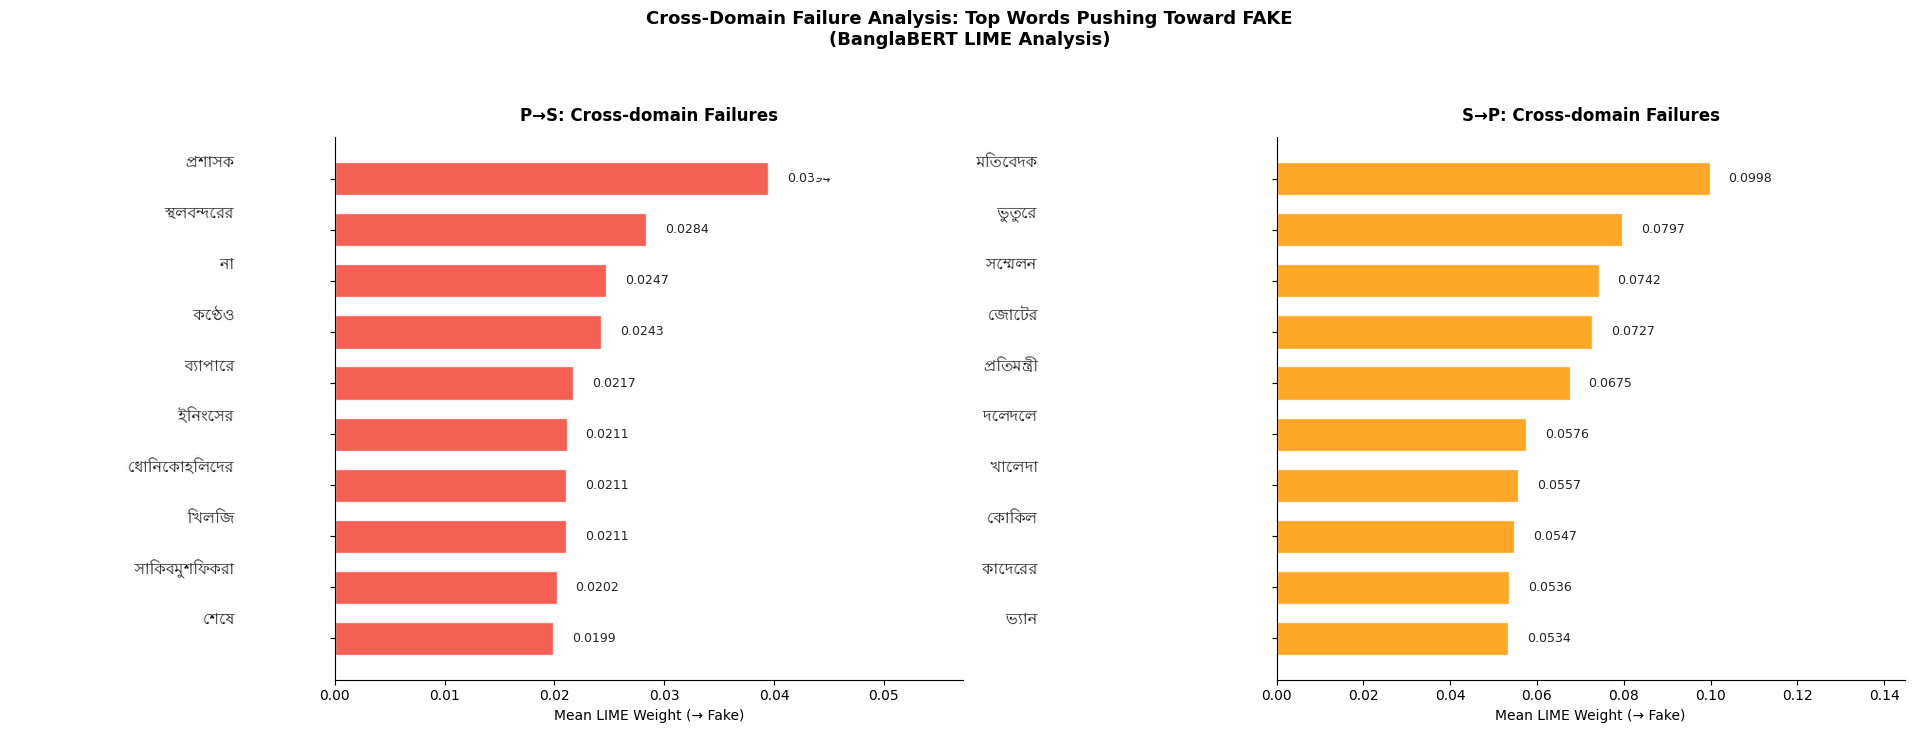

✅ PNG saved → /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF saved → /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf  ← use this in LaTeX


In [ ]:
# ============================================================
# Cell 20-Fix-11: Cross-Domain Failure LIME Figure (FIXED v3)
# Fix: top bar value label hidden behind Bengali word image
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

SAVE_DIR  = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

# ── Load CSVs ─────────────────────────────────────────────────
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# ── Top-N positive-weight words ───────────────────────────────
def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

# ── Bengali word → PIL image ──────────────────────────────────
def word_to_img_array(text, font_size=19, width=230, height=34,
                      text_color=(30, 30, 30), bg_color=(255, 255, 255)):
    font = ImageFont.truetype(FONT_PATH, font_size)
    img  = Image.new('RGB', (width, height), color=bg_color)
    draw = ImageDraw.Draw(img)
    draw.text((width - 4, height // 2), text, font=font,
              fill=text_color, anchor='rm')
    return np.array(img)

# ── Draw one panel ────────────────────────────────────────────
def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title, fontsize=12, fontweight='bold')
        return

    n     = len(tw)
    ypos  = list(range(n))
    vals  = tw['mean_weight'].tolist()
    words = tw['word'].tolist()
    max_v = max(vals)

    # ── x-axis: extend to 45% beyond max bar (more room for labels) ──
    x_max = max_v * 1.45
    ax.set_xlim(0, x_max)

    ax.barh(ypos, vals, color=color, alpha=0.85, edgecolor='white', height=0.65)
    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * n)
    ax.invert_yaxis()
    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # ── Value labels: offset = 3% of x_max (larger gap) ─────
    offset = x_max * 0.030
    for i, val in enumerate(vals):
        ax.text(val + offset, i, f'{val:.4f}',
                va='center', ha='left', fontsize=9,
                color='#222222', zorder=5)   # zorder=5 keeps it on top

    # ── Embed Bengali word images ─────────────────────────────
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    ax_bbox  = ax.get_window_extent(renderer=renderer)
    fig_bbox = ax.figure.get_window_extent(renderer=renderer)

    for i, word in enumerate(words):
        _, y_disp = ax.transData.transform((0, i))
        y_fig = y_disp / fig_bbox.height
        x_fig = ax_bbox.x0 / fig_bbox.width

        # Shift word images further LEFT so they never touch bar area
        word_ax = ax.figure.add_axes(
            [x_fig - 0.130, y_fig - 0.022, 0.120, 0.044],
            anchor='NE'
        )
        word_img = word_to_img_array(word, font_size=17, width=240, height=34)
        word_ax.imshow(word_img, aspect='auto', interpolation='lanczos')
        word_ax.axis('off')

# ── Build figure ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n(BanglaBERT LIME Analysis)',
    fontsize=13, fontweight='bold', y=1.04
)

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

# Left margin for Bengali labels, right margin for value numbers
plt.tight_layout(rect=[0.15, 0, 1, 1])
plt.subplots_adjust(wspace=0.50)   # gap between the two panels

# ── Save ──────────────────────────────────────────────────────
png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight', format='pdf')
plt.show()

print(f"✅ PNG saved → {png_path}")
print(f"✅ PDF saved → {pdf_path}  ← use this in LaTeX")

/tmp/ipykernel_3101/1846861533.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.15, 0, 1, 1])


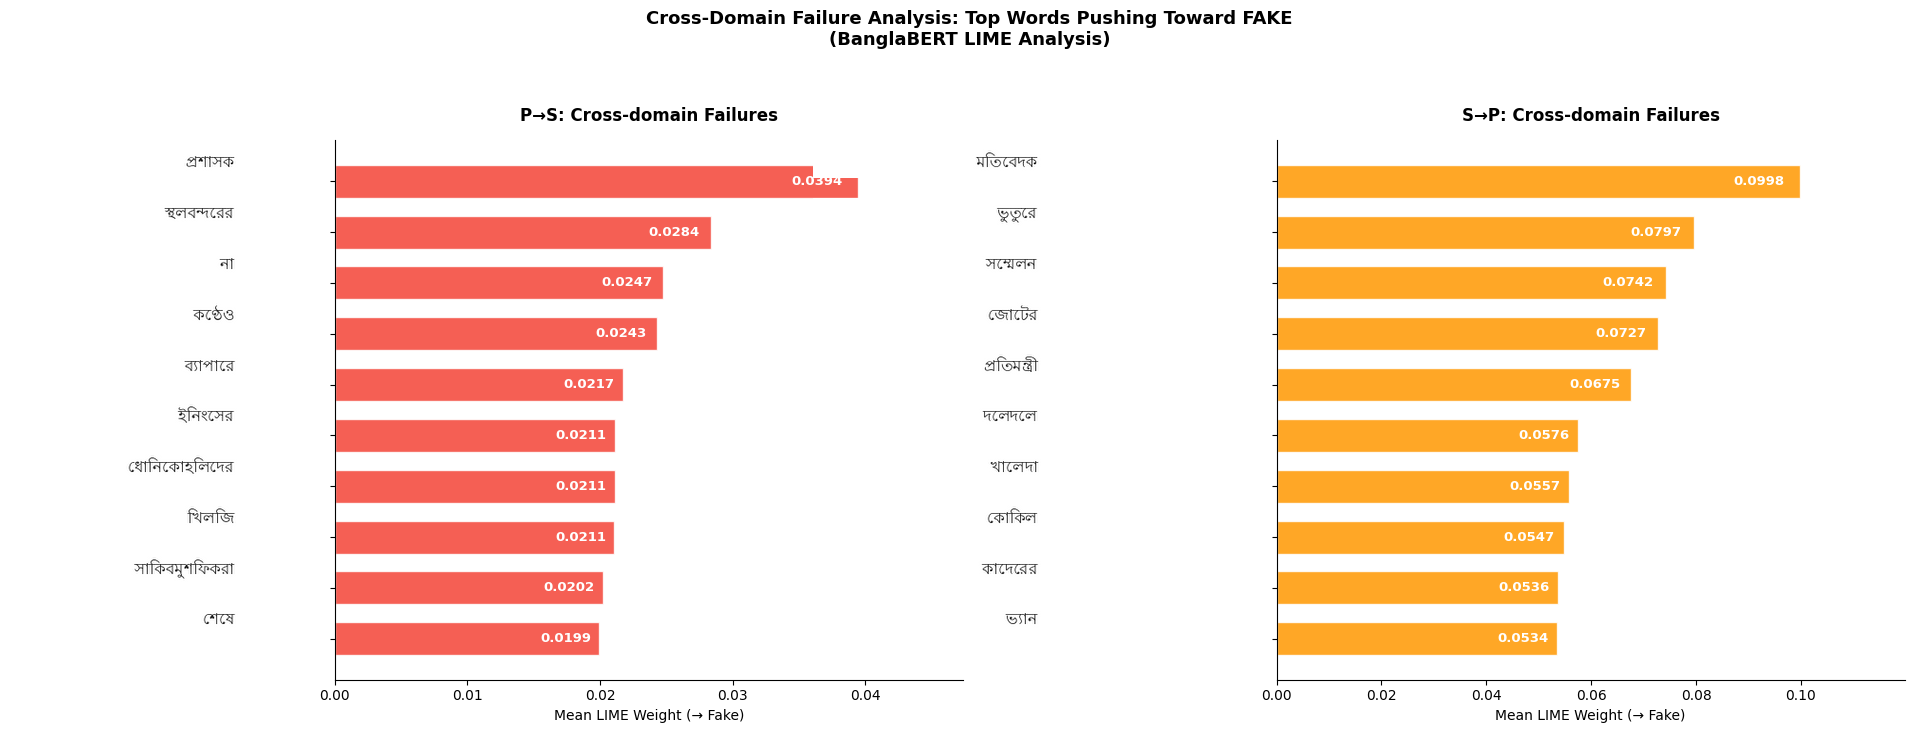

✅ PNG → /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF → /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf  ← use this in LaTeX


In [ ]:
# ============================================================
# Cell 20-Fix-FINAL: Cross-Domain Failure LIME Figure
# Fix: ALL labels placed INSIDE bars as white bold text
#      Short bars get dark label just outside
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image, ImageDraw, ImageFont

SAVE_DIR  = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

def word_to_img_array(text, font_size=19, width=230, height=34,
                      text_color=(30, 30, 30), bg_color=(255, 255, 255)):
    font = ImageFont.truetype(FONT_PATH, font_size)
    img  = Image.new('RGB', (width, height), color=bg_color)
    draw = ImageDraw.Draw(img)
    draw.text((width - 4, height // 2), text, font=font,
              fill=text_color, anchor='rm')
    return np.array(img)

def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)
    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title, fontsize=12, fontweight='bold')
        return

    n     = len(tw)
    ypos  = list(range(n))
    vals  = tw['mean_weight'].tolist()
    words = tw['word'].tolist()
    max_v = max(vals)

    # x-axis: 20% beyond max bar — labels go INSIDE, no overflow possible
    x_max = max_v * 1.20
    ax.set_xlim(0, x_max)

    bars = ax.barh(ypos, vals, color=color, alpha=0.85,
                   edgecolor='white', height=0.65)
    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * n)
    ax.invert_yaxis()
    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=14)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # threshold: bars longer than 35% of max get INSIDE white label
    threshold = max_v * 0.35
    for bar, val in zip(bars, vals):
        bw = bar.get_width()
        if bw >= threshold:
            # Inside bar — white bold, right-aligned, safe from any clipping
            ax.text(bw * 0.97, bar.get_y() + bar.get_height() / 2,
                    f'{val:.4f}',
                    va='center', ha='right',
                    fontsize=9.5, color='white',
                    fontweight='bold', zorder=10)
        else:
            # Short bar — outside, dark text
            ax.text(bw + max_v * 0.012, bar.get_y() + bar.get_height() / 2,
                    f'{val:.4f}',
                    va='center', ha='left',
                    fontsize=9.5, color='#222222', zorder=10)

    # Embed Bengali word images
    ax.figure.canvas.draw()
    renderer = ax.figure.canvas.get_renderer()
    ax_bbox  = ax.get_window_extent(renderer=renderer)
    fig_bbox = ax.figure.get_window_extent(renderer=renderer)

    for i, word in enumerate(words):
        _, y_disp = ax.transData.transform((0, i))
        y_fig = y_disp / fig_bbox.height
        x_fig = ax_bbox.x0 / fig_bbox.width

        word_ax = ax.figure.add_axes(
            [x_fig - 0.130, y_fig - 0.022, 0.120, 0.044],
            anchor='NE'
        )
        word_img = word_to_img_array(word, font_size=17, width=240, height=34)
        word_ax.imshow(word_img, aspect='auto', interpolation='lanczos')
        word_ax.axis('off')

# Build figure
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n(BanglaBERT LIME Analysis)',
    fontsize=13, fontweight='bold', y=1.04
)

for ax, (scen_label, df, color, title) in zip(axes.flat, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

plt.tight_layout(rect=[0.15, 0, 1, 1])
plt.subplots_adjust(wspace=0.50)

png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight', format='pdf')
plt.show()

print(f"✅ PNG → {png_path}")
print(f"✅ PDF → {pdf_path}  ← use this in LaTeX")

/tmp/ipykernel_3101/3667596129.py:146: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.15, 0, 1, 1])


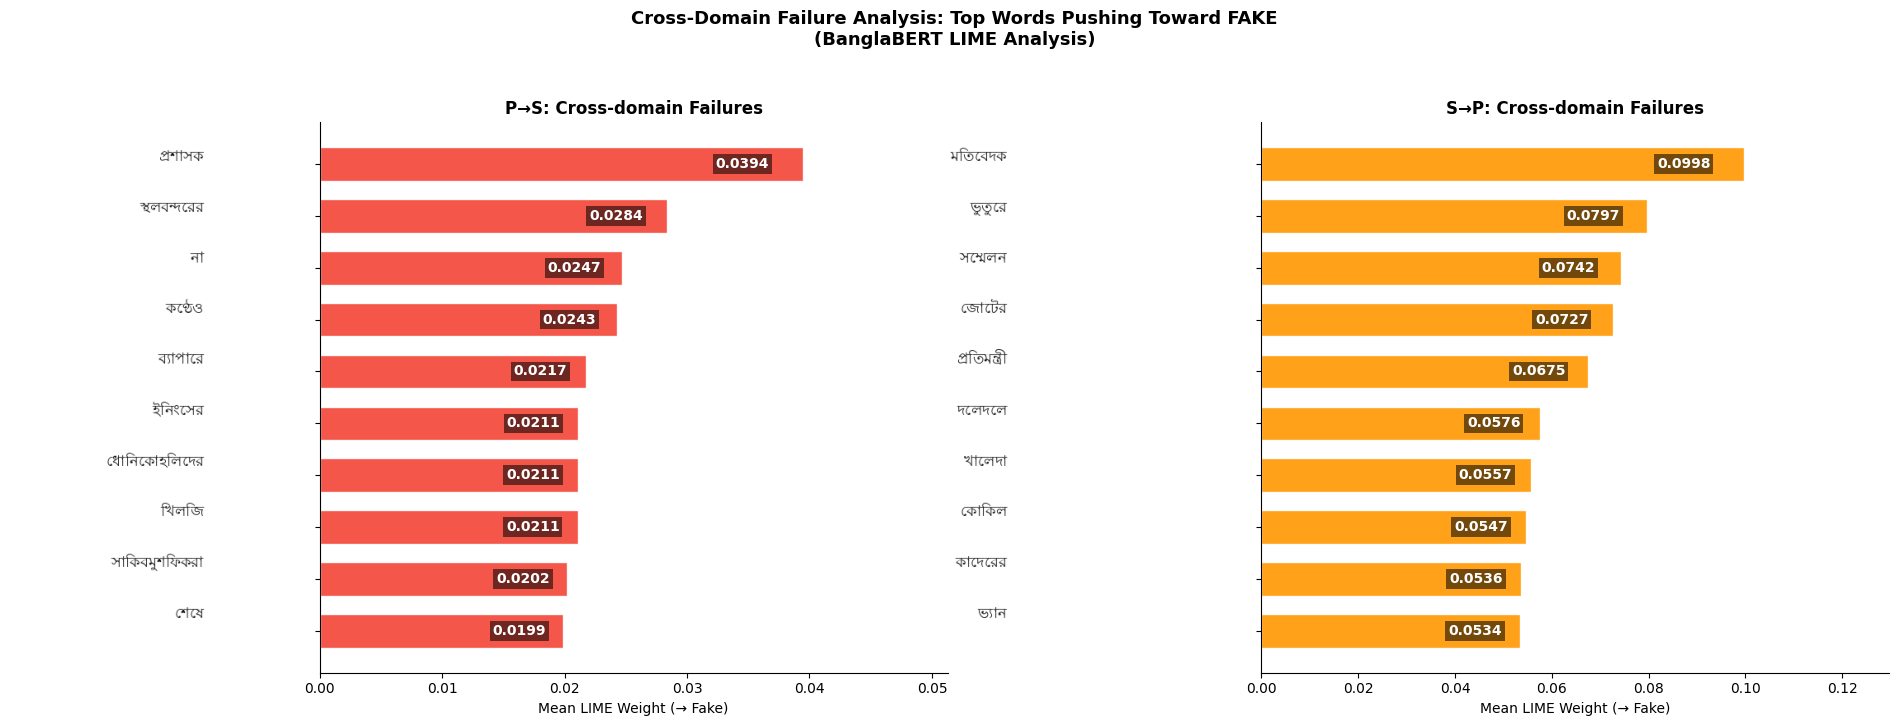

✅ PNG saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf


In [ ]:
# ============================================================
# FINAL FIXED VERSION: Cross-Domain LIME Plot (Clear Labels)
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# مسیرগুলো ঠিক আছে কিনা নিশ্চিত হও
SAVE_DIR  = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

# Load data
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

# Scenario setup
scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# Get top words
def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

# Bengali text to image
def word_to_img_array(text, font_size=18, width=240, height=34):
    font = ImageFont.truetype(FONT_PATH, font_size)
    img  = Image.new('RGB', (width, height), color=(255, 255, 255))
    draw = ImageDraw.Draw(img)
    draw.text((width - 5, height // 2), text,
              font=font, fill=(20, 20, 20), anchor='rm')
    return np.array(img)

# 🔥 MAIN FIXED PLOT FUNCTION
def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)

    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        return

    ypos  = np.arange(len(tw))
    vals  = tw['mean_weight'].values
    words = tw['word'].values
    max_v = vals.max()

    ax.set_xlim(0, max_v * 1.30)

    bars = ax.barh(ypos, vals,
                   color=color,
                   alpha=0.9,
                   edgecolor='white',
                   height=0.65)

    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * len(words))
    ax.invert_yaxis()

    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    threshold = max_v * 0.35

    # 🔥 VALUE LABELS (FIXED VISIBILITY)
    for i, bar in enumerate(bars):
        bw = bar.get_width()
        y  = bar.get_y() + bar.get_height() / 2
        val = vals[i]

        if bw >= threshold:
            # Inside bar with background
            ax.text(
                bw * 0.93, y,
                f'{val:.4f}',
                ha='right', va='center',
                fontsize=10,
                color='white',
                fontweight='bold',
                bbox=dict(
                    facecolor='black',
                    alpha=0.55,
                    pad=2,
                    edgecolor='none'
                ),
                clip_on=False
            )
        else:
            # Outside small bars
            ax.text(
                bw + max_v * 0.02, y,
                f'{val:.4f}',
                ha='left', va='center',
                fontsize=10,
                color='#222222',
                fontweight='bold',
                clip_on=False
            )

    # Bengali word labels (image-based)
    try:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()

        ax_bbox  = ax.get_window_extent(renderer=renderer)
        fig_bbox = ax.figure.get_window_extent(renderer=renderer)

        for i, word in enumerate(words):
            _, y_disp = ax.transData.transform((0, i))
            y_fig = y_disp / fig_bbox.height
            x_fig = ax_bbox.x0 / fig_bbox.width

            word_ax = ax.figure.add_axes(
                [x_fig - 0.13, y_fig - 0.02, 0.12, 0.04]
            )

            word_img = word_to_img_array(word)
            word_ax.imshow(word_img)
            word_ax.axis('off')

    except Exception as e:
        print("Word rendering skipped:", e)

# ================== BUILD FIGURE ==================
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n(BanglaBERT LIME Analysis)',
    fontsize=13, fontweight='bold', y=1.03
)

for ax, (scen_label, df, color, title) in zip(axes, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

plt.tight_layout(rect=[0.15, 0, 1, 1])
plt.subplots_adjust(wspace=0.5)

# Save outputs
png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight')

plt.show()

print("✅ PNG saved:", png_path)
print("✅ PDF saved:", pdf_path)

✅ Using Noto Sans Bengali Bold


/tmp/ipykernel_1267/2342423057.py:148: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.15, 0, 1, 1])


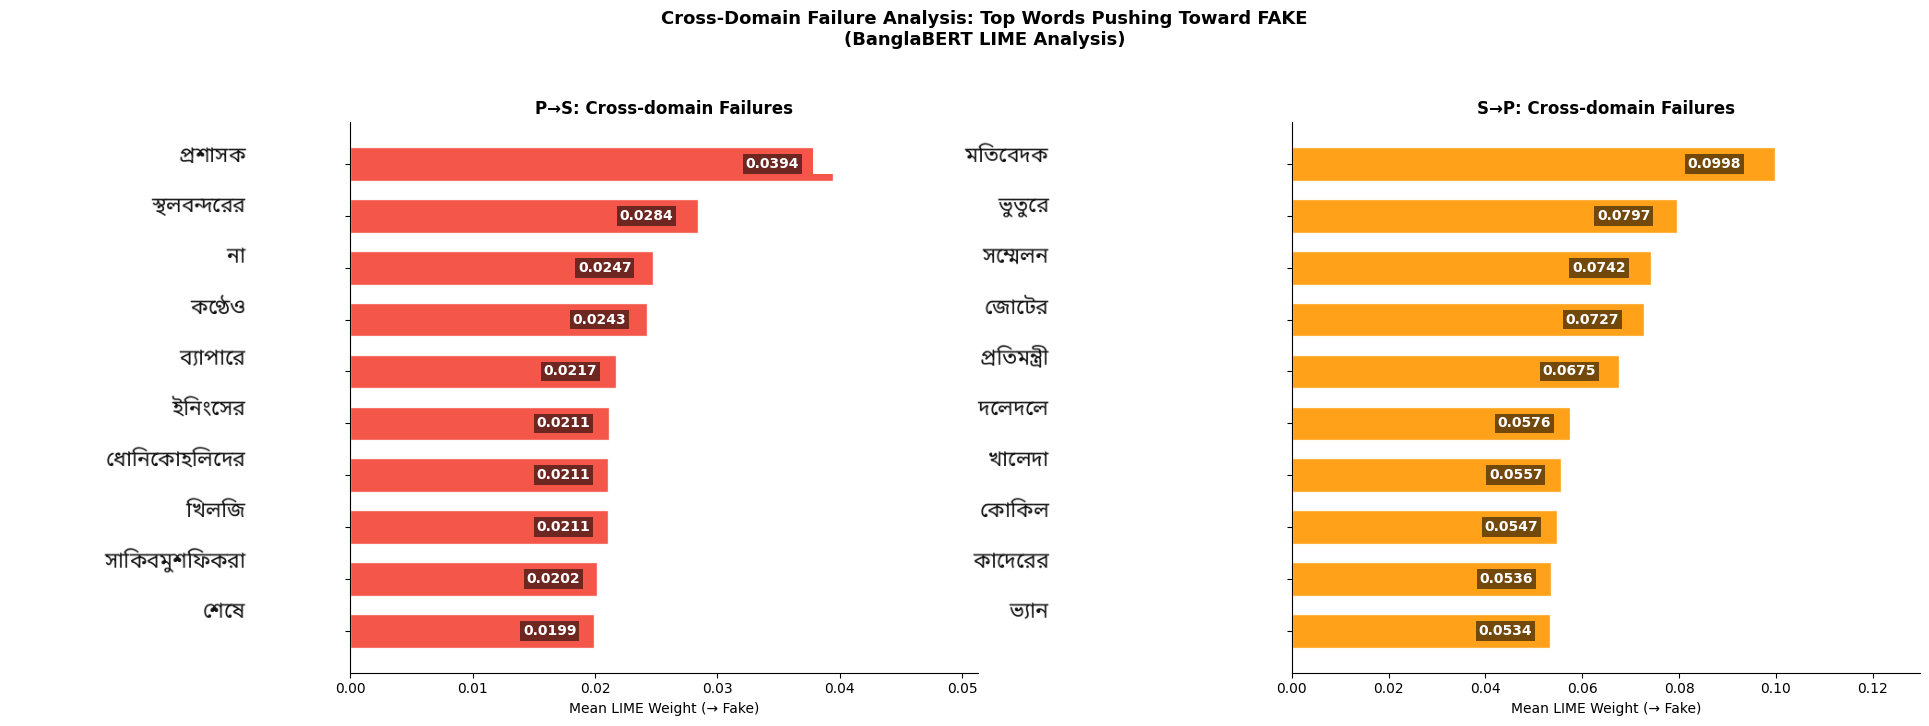

✅ PNG saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf


In [ ]:
# ============================================================
# FINAL FIXED VERSION: Cross-Domain LIME Plot (Bold Bengali)
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# ── Download Noto Sans Bengali Bold (supports bold weight) ───
os.system("wget -q -O /tmp/NotoSansBengali-Bold.ttf "
          "https://github.com/google/fonts/raw/main/ofl/notosansbengali/NotoSansBengali%5Bwdth%2Cwght%5D.ttf")
BOLD_FONT_PATH = '/tmp/NotoSansBengali-Bold.ttf'

SAVE_DIR  = '/content/drive/MyDrive/banglabert_weights/'
FONT_PATH = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

# ── Verify bold font downloaded ───────────────────────────────
if os.path.exists(BOLD_FONT_PATH) and os.path.getsize(BOLD_FONT_PATH) > 10000:
    ACTIVE_FONT = BOLD_FONT_PATH
    print("✅ Using Noto Sans Bengali Bold")
else:
    ACTIVE_FONT = FONT_PATH
    print("⚠️ Bold font download failed — falling back to Lohit-Bengali")

# ── Load data ─────────────────────────────────────────────────
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# ── Top-N positive-weight words ───────────────────────────────
def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

# ── Bengali word → PIL image (LARGER + BOLD) ─────────────────
# CHANGED: font_size 18→23, width 240→260, height 34→38
# CHANGED: uses ACTIVE_FONT (bold Noto Sans Bengali)
def word_to_img_array(text, font_size=23, width=260, height=38):
    font = ImageFont.truetype(ACTIVE_FONT, font_size)   # ← bold font
    img  = Image.new('RGB', (width, height), color=(255, 255, 255))
    draw = ImageDraw.Draw(img)
    draw.text((width - 5, height // 2), text,
              font=font, fill=(20, 20, 20), anchor='rm')
    return np.array(img)

# ── Draw one panel ────────────────────────────────────────────
def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)

    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        return

    ypos  = np.arange(len(tw))
    vals  = tw['mean_weight'].values
    words = tw['word'].values
    max_v = vals.max()

    ax.set_xlim(0, max_v * 1.30)

    bars = ax.barh(ypos, vals,
                   color=color,
                   alpha=0.9,
                   edgecolor='white',
                   height=0.65)

    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * len(words))
    ax.invert_yaxis()

    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=10)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    threshold = max_v * 0.35

    # Value labels
    for i, bar in enumerate(bars):
        bw  = bar.get_width()
        y   = bar.get_y() + bar.get_height() / 2
        val = vals[i]

        if bw >= threshold:
            ax.text(
                bw * 0.93, y,
                f'{val:.4f}',
                ha='right', va='center',
                fontsize=10, color='white', fontweight='bold',
                bbox=dict(facecolor='black', alpha=0.55,
                          pad=2, edgecolor='none'),
                clip_on=False
            )
        else:
            ax.text(
                bw + max_v * 0.02, y,
                f'{val:.4f}',
                ha='left', va='center',
                fontsize=10, color='#222222', fontweight='bold',
                clip_on=False
            )

    # Bengali word images
    try:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()
        ax_bbox  = ax.get_window_extent(renderer=renderer)
        fig_bbox = ax.figure.get_window_extent(renderer=renderer)

        for i, word in enumerate(words):
            _, y_disp = ax.transData.transform((0, i))
            y_fig = y_disp / fig_bbox.height
            x_fig = ax_bbox.x0 / fig_bbox.width

            # CHANGED: taller/wider inset box to fit larger bold font
            word_ax = ax.figure.add_axes(
                [x_fig - 0.14, y_fig - 0.025, 0.13, 0.050]
            )
            word_img = word_to_img_array(word)
            word_ax.imshow(word_img)
            word_ax.axis('off')

    except Exception as e:
        print("Word rendering skipped:", e)

# ── Build figure ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(19, 7))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n(BanglaBERT LIME Analysis)',
    fontsize=13, fontweight='bold', y=1.03
)

for ax, (scen_label, df, color, title) in zip(axes, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

plt.tight_layout(rect=[0.15, 0, 1, 1])
plt.subplots_adjust(wspace=0.5)

# ── Save ──────────────────────────────────────────────────────
png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight')
plt.show()

print("✅ PNG saved:", png_path)
print("✅ PDF saved:", pdf_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


✅ Using Noto Sans Bengali Bold


/tmp/ipykernel_1267/9827273.py:161: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.17, 0, 1, 1])


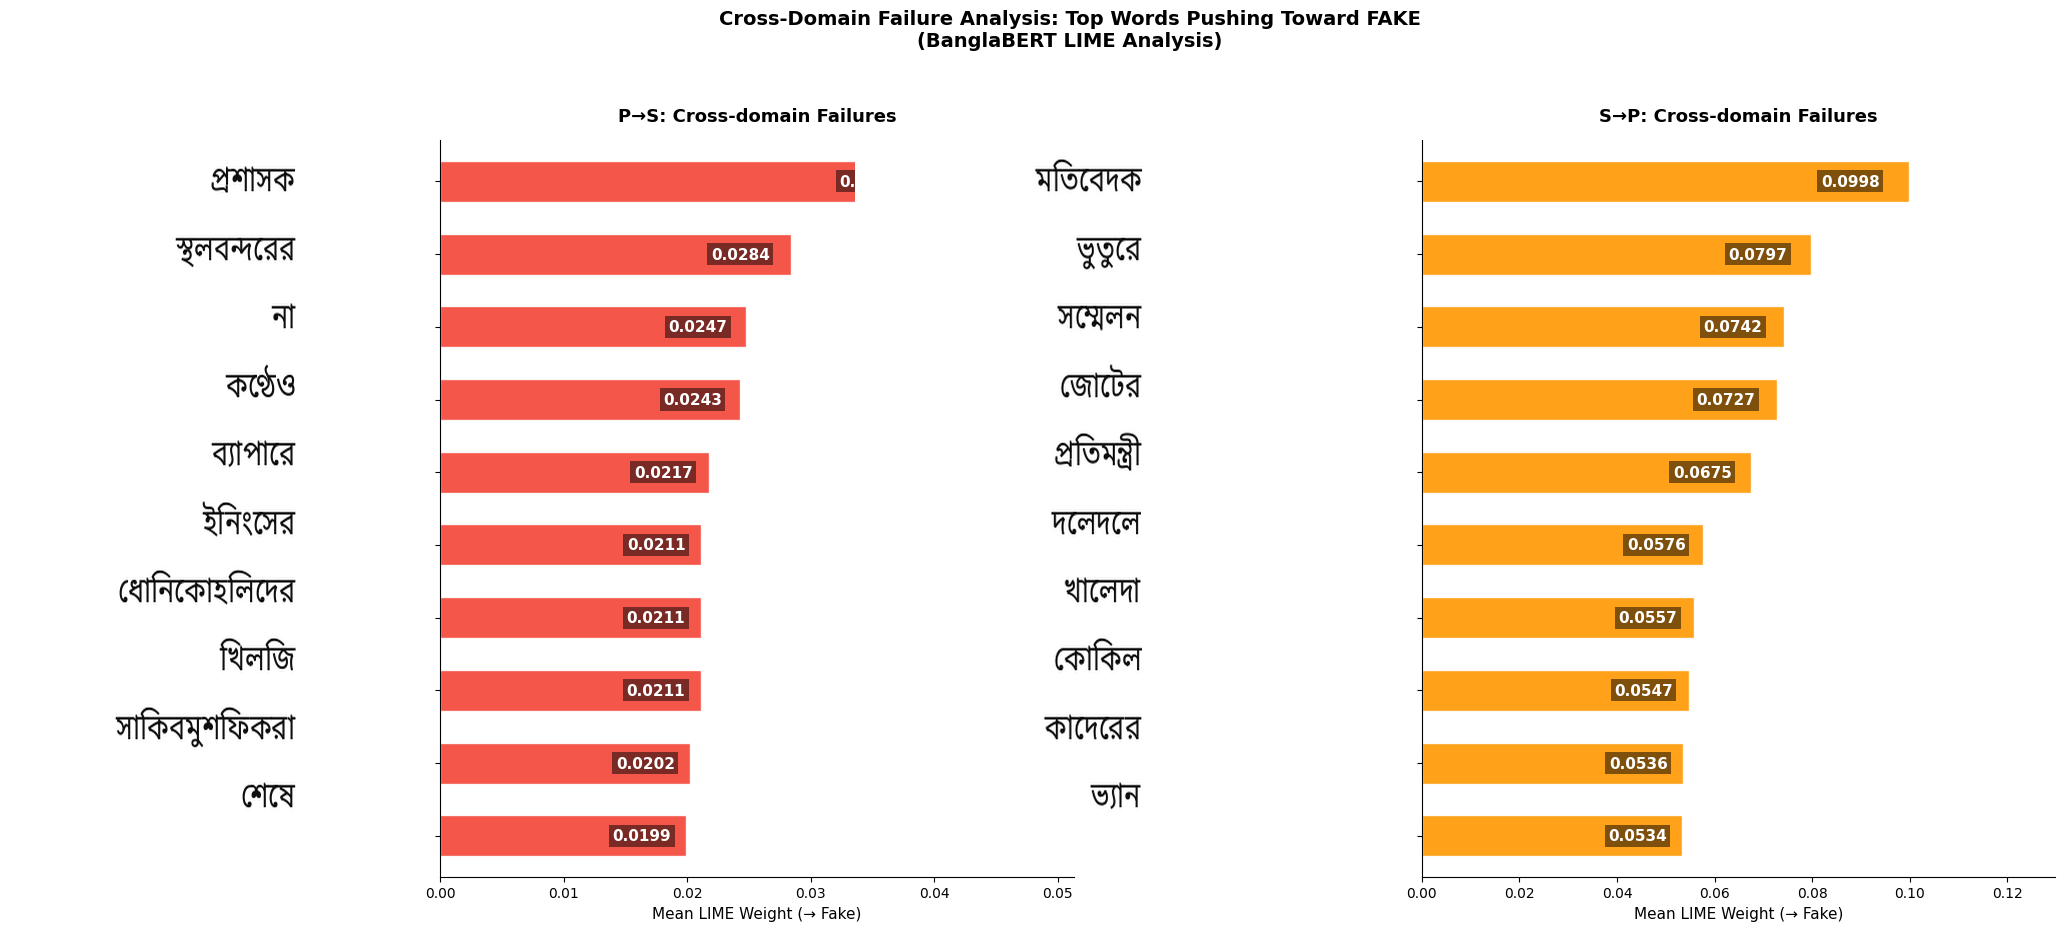

✅ PNG saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf


In [ ]:
# ============================================================
# FINAL VERSION: Cross-Domain LIME Plot (Large Bold Bengali)
# Larger words, increased row height, no overlap
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# ── Download Noto Sans Bengali Bold ──────────────────────────
os.system("wget -q -O /tmp/NotoSansBengali-Bold.ttf "
          "https://github.com/google/fonts/raw/main/ofl/notosansbengali/NotoSansBengali%5Bwdth%2Cwght%5D.ttf")
BOLD_FONT_PATH = '/tmp/NotoSansBengali-Bold.ttf'
FALLBACK_FONT  = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

if os.path.exists(BOLD_FONT_PATH) and os.path.getsize(BOLD_FONT_PATH) > 10000:
    ACTIVE_FONT = BOLD_FONT_PATH
    print("✅ Using Noto Sans Bengali Bold")
else:
    ACTIVE_FONT = FALLBACK_FONT
    print("⚠️ Falling back to Lohit-Bengali")

SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'

# ── Load data ─────────────────────────────────────────────────
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# ── Top-N words ───────────────────────────────────────────────
def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

# ── Bengali word → PIL image ──────────────────────────────────
# font_size=27  → large and bold
# width=290, height=44 → enough room, no clipping
def word_to_img_array(text, font_size=27, width=290, height=44):
    font = ImageFont.truetype(ACTIVE_FONT, font_size)
    img  = Image.new('RGB', (width, height), color=(255, 255, 255))
    draw = ImageDraw.Draw(img)
    draw.text((width - 5, height // 2), text,
              font=font, fill=(15, 15, 15), anchor='rm')
    return np.array(img)

# ── Draw one panel ────────────────────────────────────────────
def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)

    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        return

    n     = len(tw)
    # Spread bars further apart to prevent word image overlap
    # ypos with step=1.6 gives vertical breathing room
    ypos  = np.arange(n) * 1.6
    vals  = tw['mean_weight'].values
    words = tw['word'].values
    max_v = vals.max()

    ax.set_xlim(0, max_v * 1.30)
    # Set y-axis limits to match spaced ypos
    ax.set_ylim(-0.9, ypos[-1] + 0.9)

    bars = ax.barh(ypos, vals,
                   color=color,
                   alpha=0.90,
                   edgecolor='white',
                   height=0.90)          # taller bars to match spacing

    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * n)
    ax.invert_yaxis()

    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=14)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='x', labelsize=10)

    threshold = max_v * 0.35

    # Value labels
    for i, bar in enumerate(bars):
        bw  = bar.get_width()
        y   = bar.get_y() + bar.get_height() / 2
        val = vals[i]

        if bw >= threshold:
            # Inside bar — white bold with dark background box
            ax.text(
                bw * 0.94, y,
                f'{val:.4f}',
                ha='right', va='center',
                fontsize=11, color='white', fontweight='bold',
                bbox=dict(facecolor='black', alpha=0.50,
                          pad=2.5, edgecolor='none'),
                clip_on=False, zorder=10
            )
        else:
            # Short bar — outside dark label
            ax.text(
                bw + max_v * 0.020, y,
                f'{val:.4f}',
                ha='left', va='center',
                fontsize=11, color='#111111', fontweight='bold',
                clip_on=False, zorder=10
            )

    # ── Bengali word images ───────────────────────────────────
    try:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()
        ax_bbox  = ax.get_window_extent(renderer=renderer)
        fig_bbox = ax.figure.get_window_extent(renderer=renderer)

        for i, word in enumerate(words):
            # Use actual bar y-center (spaced ypos)
            _, y_disp = ax.transData.transform((0, ypos[i]))
            y_fig = y_disp / fig_bbox.height
            x_fig = ax_bbox.x0 / fig_bbox.width

            # Inset box sized to match font_size=27, height=44
            word_ax = ax.figure.add_axes(
                [x_fig - 0.155, y_fig - 0.032, 0.145, 0.064],
                anchor='NE'
            )
            word_img = word_to_img_array(word)
            word_ax.imshow(word_img, aspect='auto', interpolation='lanczos')
            word_ax.axis('off')

    except Exception as e:
        print("Word rendering skipped:", e)

# ── Build figure ──────────────────────────────────────────────
# Taller figure (height=9) to accommodate larger spaced words
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n'
    '(BanglaBERT LIME Analysis)',
    fontsize=14, fontweight='bold', y=1.03
)

for ax, (scen_label, df, color, title) in zip(axes, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

# Extra left margin for larger Bengali labels
plt.tight_layout(rect=[0.17, 0, 1, 1])
plt.subplots_adjust(wspace=0.55)

# ── Save ──────────────────────────────────────────────────────
png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight')
plt.show()

print("✅ PNG saved:", png_path)
print("✅ PDF saved:", pdf_path)

✅ Using Noto Sans Bengali Bold


/tmp/ipykernel_1267/4244120609.py:149: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0.17, 0, 1, 1])


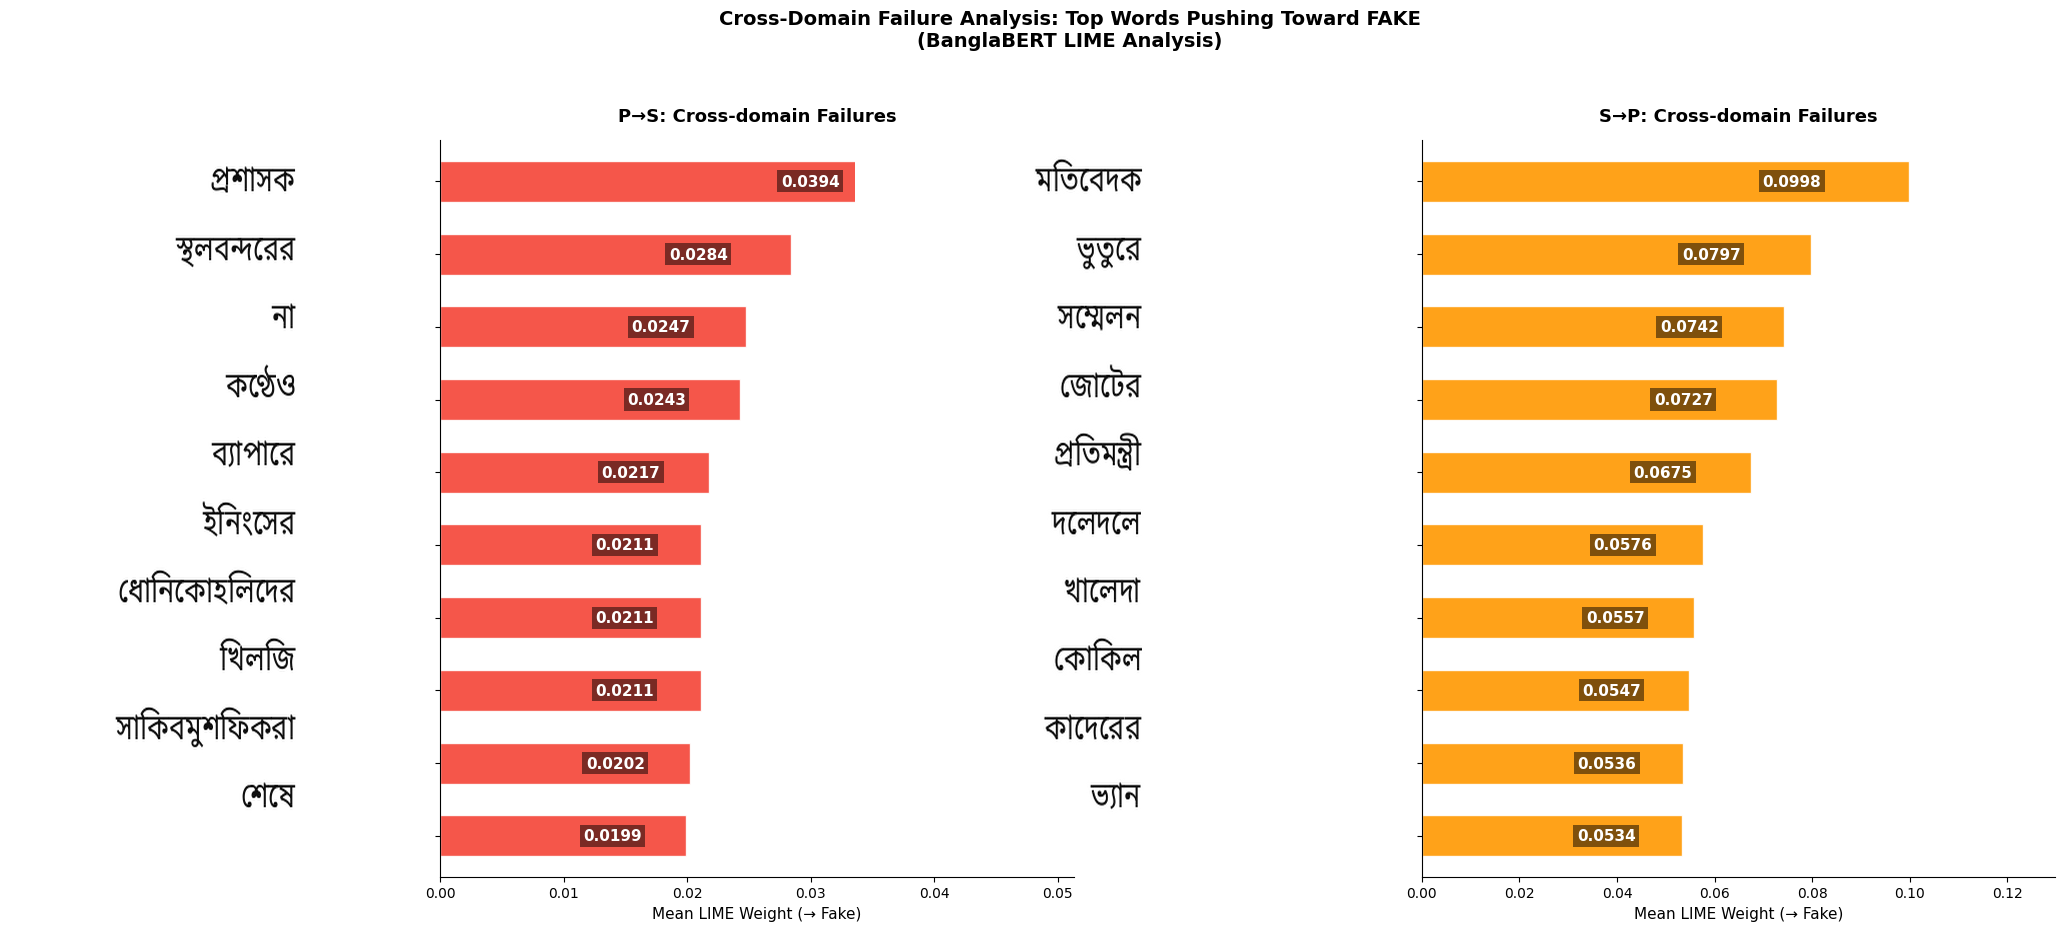

✅ PNG saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.png
✅ PDF saved: /content/drive/MyDrive/banglabert_weights/fig_lime_crossdomain.pdf


In [ ]:
# ============================================================
# FINAL VERSION: Cross-Domain LIME Plot (Large Bold Bengali)
# Fix: প্রশাসক value fully visible (label shifted left on long bars)
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

# ── Download Noto Sans Bengali Bold ──────────────────────────
os.system("wget -q -O /tmp/NotoSansBengali-Bold.ttf "
          "https://github.com/google/fonts/raw/main/ofl/notosansbengali/NotoSansBengali%5Bwdth%2Cwght%5D.ttf")
BOLD_FONT_PATH = '/tmp/NotoSansBengali-Bold.ttf'
FALLBACK_FONT  = '/usr/share/fonts/truetype/lohit-bengali/Lohit-Bengali.ttf'

if os.path.exists(BOLD_FONT_PATH) and os.path.getsize(BOLD_FONT_PATH) > 10000:
    ACTIVE_FONT = BOLD_FONT_PATH
    print("✅ Using Noto Sans Bengali Bold")
else:
    ACTIVE_FONT = FALLBACK_FONT
    print("⚠️ Falling back to Lohit-Bengali")

SAVE_DIR = '/content/drive/MyDrive/banglabert_weights/'

# ── Load data ─────────────────────────────────────────────────
lime_ps = pd.read_csv(SAVE_DIR + 'lime_ps.csv')
lime_sp = pd.read_csv(SAVE_DIR + 'lime_sp.csv')

scen_list = [
    ('P→S (Cross-domain Failure)', lime_ps, '#F44336', 'P→S: Cross-domain Failures'),
    ('S→P (Cross-domain Failure)', lime_sp, '#FF9800', 'S→P: Cross-domain Failures'),
]

# ── Top-N words ───────────────────────────────────────────────
def top_words_signed(df, scenario, class_name, n=10):
    subset  = df[(df['scenario'] == scenario) & (df['class'] == class_name)]
    grouped = subset.groupby('word')['weight'].mean().reset_index()
    grouped.columns = ['word', 'mean_weight']
    grouped = grouped[grouped['mean_weight'] > 0].sort_values(
        'mean_weight', ascending=False)
    return grouped.head(n).reset_index(drop=True)

# ── Bengali word → PIL image ──────────────────────────────────
def word_to_img_array(text, font_size=27, width=290, height=44):
    font = ImageFont.truetype(ACTIVE_FONT, font_size)
    img  = Image.new('RGB', (width, height), color=(255, 255, 255))
    draw = ImageDraw.Draw(img)
    draw.text((width - 5, height // 2), text,
              font=font, fill=(15, 15, 15), anchor='rm')
    return np.array(img)

# ── Draw one panel ────────────────────────────────────────────
def draw_lime_subplot(ax, df, scen_label, color, title):
    tw = top_words_signed(df, scen_label, 'Fake', n=10)

    if tw.empty:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center')
        ax.set_title(title)
        return

    n     = len(tw)
    ypos  = np.arange(n) * 1.6
    vals  = tw['mean_weight'].values
    words = tw['word'].values
    max_v = vals.max()

    ax.set_xlim(0, max_v * 1.30)
    ax.set_ylim(-0.9, ypos[-1] + 0.9)

    bars = ax.barh(ypos, vals,
                   color=color, alpha=0.90,
                   edgecolor='white', height=0.90)

    ax.set_yticks(ypos)
    ax.set_yticklabels([''] * n)
    ax.invert_yaxis()
    ax.set_xlabel('Mean LIME Weight (→ Fake)', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=14)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.tick_params(axis='x', labelsize=10)

    threshold = max_v * 0.35

    # Value labels
    for i, bar in enumerate(bars):
        bw  = bar.get_width()
        y   = bar.get_y() + bar.get_height() / 2
        val = vals[i]

        if bw >= threshold:
            # ── KEY FIX: use 0.82 instead of 0.94 ────────────
            # Shifts label well away from bar edge — no clipping
            ax.text(
                bw * 0.82, y,
                f'{val:.4f}',
                ha='right', va='center',
                fontsize=11, color='white', fontweight='bold',
                bbox=dict(facecolor='black', alpha=0.50,
                          pad=2.5, edgecolor='none'),
                clip_on=False, zorder=10
            )
        else:
            ax.text(
                bw + max_v * 0.020, y,
                f'{val:.4f}',
                ha='left', va='center',
                fontsize=11, color='#111111', fontweight='bold',
                clip_on=False, zorder=10
            )

    # ── Bengali word images ───────────────────────────────────
    try:
        ax.figure.canvas.draw()
        renderer = ax.figure.canvas.get_renderer()
        ax_bbox  = ax.get_window_extent(renderer=renderer)
        fig_bbox = ax.figure.get_window_extent(renderer=renderer)

        for i, word in enumerate(words):
            _, y_disp = ax.transData.transform((0, ypos[i]))
            y_fig = y_disp / fig_bbox.height
            x_fig = ax_bbox.x0 / fig_bbox.width

            word_ax = ax.figure.add_axes(
                [x_fig - 0.155, y_fig - 0.032, 0.145, 0.064],
                anchor='NE'
            )
            word_img = word_to_img_array(word)
            word_ax.imshow(word_img, aspect='auto', interpolation='lanczos')
            word_ax.axis('off')

    except Exception as e:
        print("Word rendering skipped:", e)

# ── Build figure ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

fig.suptitle(
    'Cross-Domain Failure Analysis: Top Words Pushing Toward FAKE\n'
    '(BanglaBERT LIME Analysis)',
    fontsize=14, fontweight='bold', y=1.03
)

for ax, (scen_label, df, color, title) in zip(axes, scen_list):
    draw_lime_subplot(ax, df, scen_label, color, title)

plt.tight_layout(rect=[0.17, 0, 1, 1])
plt.subplots_adjust(wspace=0.55)

# ── Save ──────────────────────────────────────────────────────
png_path = SAVE_DIR + 'fig_lime_crossdomain.png'
pdf_path = SAVE_DIR + 'fig_lime_crossdomain.pdf'

plt.savefig(png_path, dpi=200, bbox_inches='tight')
plt.savefig(pdf_path, dpi=300, bbox_inches='tight')
plt.show()

print("✅ PNG saved:", png_path)
print("✅ PDF saved:", pdf_path)